# Toolbox Augmentation and Evolution: Teaching an Agent to Find — and Call — Its Own Tools

Every tool your agent has ever called started life as a docstring written by someone in a hurry. *"Fetch a claim."* *"Escalate a claim."* Perfectly clear to the engineer who wrote it. Rather less clear to a model that has to work out, from those three words, what your team means when it asks for something in its own shorthand.

The usual fix is to tell engineers to write better docstrings. That works about as well as telling them to write better commit messages.

This notebook takes the other route. We let the agent's memory do the work: MemoRizz **enriches each tool's description when it's registered**, then **revises it from the tool log** as real usage shows where selection and calling go wrong. No fine-tuning, no prompt surgery, and nothing the tool's author wrote gets overwritten.

## Key takeaways

- ***A tool has two readers.*** *The router decides whether the model ever sees the tool; the model decides how to call it. They fail differently, so they need different fixes.*
- ***Augmentation is a guess; evolution is a correction.*** *At registration nobody knows how your team actually talks. The tool log does.*
- ***The tool log is training data you already own.*** *Every refused call and every request someone had to make twice is a labelled example — you just weren't reading it.*
- ***The model proposes; the code decides.*** *A usage note has to rest on failed calls the code can count. An example request has to rest on requests that really missed. A "Not for" line has to name the tool that served them.*
- ***An example is a retrieval key, never an instruction.*** *The desk's wording goes to the router. The model is shown notes about the tool, written in the catalogue's voice — never a user's sentence.*
- ***A tool should know its neighbours.*** *When requests keep landing on one tool and being served by another, the fix is a line on the first: "Not for this; use that."*
- ***Add, never rewrite.*** *The author's docstring and the argument schema are off limits. Learning goes under its own heading, where you can see it and take it back.*
- ***Keep a control.*** *"It got better after lunch" proves nothing on its own. An identical desk that learned nothing tells you what the learning was worth.*

## How this notebook is organised

| Part | What it covers | What you'll have at the end |
|---|---|---|
| **1 · The use case** | One morning on Calderwood's claims desk, and why its frictions are a memory problem | The two failures named, and the loop that fixes them on one page |
| **2 · Setup** | The store, the models, the shared Calderwood world | A memory provider every later cell writes to |
| **3 · The toolbox: written, measured, augmented** | Twelve terse tools, an evaluation set, and enrichment at registration | A baseline number, and a catalogue that knows ordinary English |
| **4 · A morning's work** | Two identical desks work the same requests; then we read the tool log | The evidence: refused calls, and requests made twice |
| **5 · Learning from the log** | `review_tools()`, the code's checks, approval, and who reads which words | Revised catalogue entries on one desk only: notes and "Not for" lines for the model, examples for the router |
| **6 · The comparison** | The same afternoon on both desks, the tools nobody reaches, the scorecard, undo | What the learning was worth, against a control |
| **7 · In the UI, limits and FAQ** | Where to see all of it in the MemoRizz UI; what this does and doesn't show | The pages to open, and an honest list of what's missing |

# Part 1 · The use case

This part sets the scene and names the problem. You'll meet the desk, watch three small frictions happen in one morning, and see why none of them is a model bug or a tool bug. By the end you'll have the vocabulary the rest of the notebook uses — *calling error*, *selection miss*, *confusion pair*, *catalogue entry*, *revision* — and a picture of the whole loop.

## The use case: one morning on Calderwood's home claims desk

Meet the cast. We'll stay with them for the whole notebook (and the whole series).

| Who | What they are |
|---|---|
| **Calderwood Insurance** | A UK insurer. Fictional, which is the point: nothing about its systems, codes or vocabulary is in any model's training data. |
| **Ada** | Calderwood's internal claims support assistant. She has twelve tools into the claims systems: **Beacon** (claims), **Atlas** (policies), **Tally** (payments) and **the Ringfence** (sanctions screening). |
| **Priya Shah** | A Grade 2 claims handler. Fast, precise, and — like every expert — speaks in shorthand. |
| **Tom Okafor** | A Grade 1 handler, newer to the desk. Same shorthand, less inclination to check what the assistant actually did. |
| **The control desk** | Ada's identical twin: same model, same tools, same descriptions, same morning of work. The one difference is that nobody ever reviews her tool log. She is our "no continual learning" baseline. |

It's a Monday in January 2027, 9:04. Priya types:

> *Pull up 608520 for me.*

Ada calls `beacon_lookup_claim("608520")`. Beacon refuses: a claim reference is `CW-608520`, not `608520`. Ada reads the error, tries again with the prefix, and answers. Priya never sees the stumble. **It will happen again on the next claim, and the one after that — every one a wasted model call.**

At 9:12 a customer's video won't go on the file:

> *Attach the customer's 40MB video to 608733.*

Beacon rejects it with **BCN-217**: attachments stop at 25MB. Ada reads the error, relays it, and Priya gets her answer one refused call late. (Anyone who has been on the desk a month knows the limit. Ada has been on the desk a year and finds out afresh every time.)

At 9:20 Priya types:

> *610087 is a large loss.*

At Calderwood that sentence is an instruction. Any claim over £50,000 belongs to the **Large Loss Unit**, so "it's a large loss" means *send it to the LLU*. The tool that does it is `refer_llu`, described, in full, as *"Escalate a claim."* No model has ever seen those two things connected. So Ada does something plausible instead — notes it, perhaps, or looks the claim up and reports the reserve. Priya sighs and spells it out: *"A large loss goes to the LLU. Escalate that claim."*

Three small frictions. None is a bug in the model, and none is a bug in the tools.

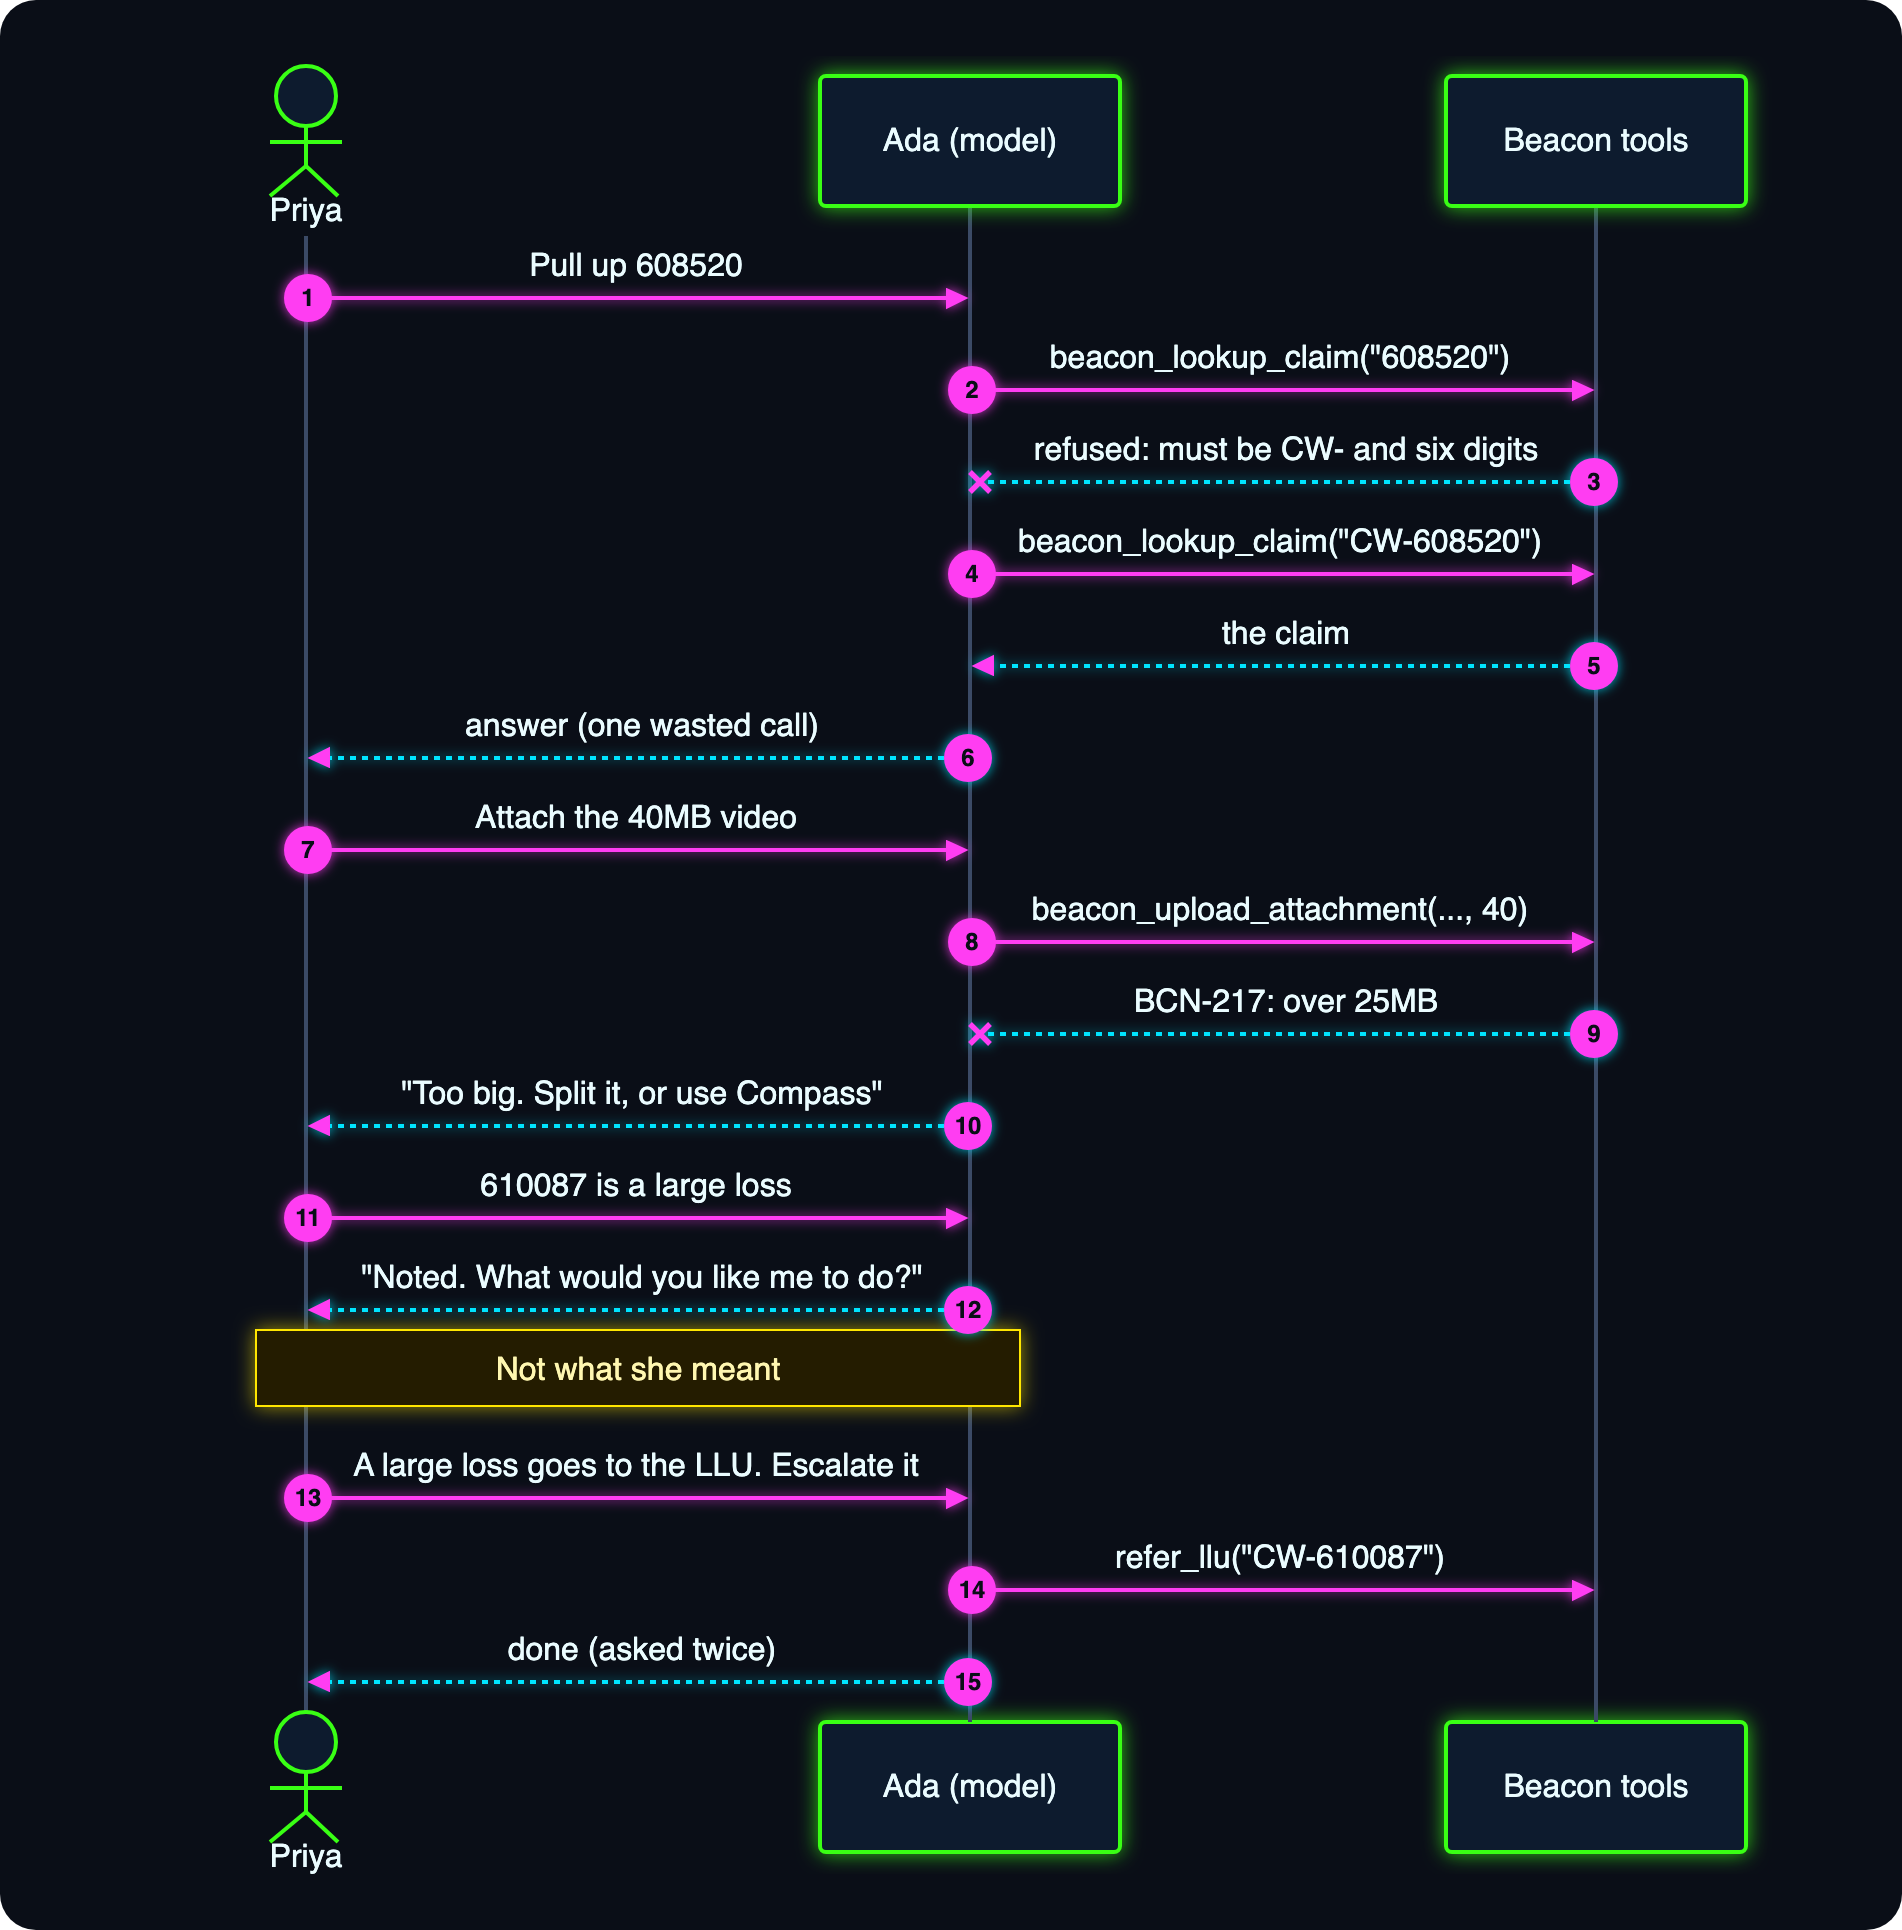

Here's the uncomfortable part. **Tomorrow morning, Ada will make exactly the same mistakes.** She learned nothing, because there's nowhere for the lesson to live: the model is stateless, and the tool descriptions are frozen at whatever the engineer typed.

By the end of this notebook, they won't be frozen. Ada will pass the full claim reference on her first call and know about the 25MB limit before she hits it — for Priya, for Tom, for anyone at the desk. Her catalogue will hold the desk's wording for a large loss, and her tools will have started to say what they are *not* for. And we'll have an identical twin who learned nothing, to show which of those was the learning and which was luck.

## Why this is a memory problem

There are two ways to make Ada better at her job.

One is to change the model: collect examples, fine-tune, redeploy. The other is to leave the weights alone and change what the model is *shown*. **Continual learning in token space is the practice of improving an agent's behaviour by revising the tokens its harness puts in front of the model — instructions, memories, skills, tool descriptions — rather than the model's weights.**

That route has three properties that matter in production: what the agent learned is **inspectable** (it's text; you can read it and review it), **reversible** (a bad lesson is one `undo` away, not a retraining run) and **portable** (swap the model underneath and the learning comes with you). It has a cost too — every learned token is paid for on every call that carries it — which is why everything here is bounded, gated and measured.

**The intelligence plane is the model layer and everything that helps it think: the LLM, its prompts, its reasoning strategies such as planning and tool selection, and the memory and retrieval that supply context.** Its job is *decision quality*. Ada calling the wrong tool isn't a networking problem or a database problem. It's an intelligence plane problem, and MemoRizz makes memory the foundation of that plane: which tools the model is offered, and how they're described, is a retrieval decision over a memory store called the **toolbox**. Improve that memory and the model makes better decisions without knowing anything changed.

### Where this fits

This is the fourth of five notebooks. Each takes one type of memory and shows how it improves with use — the *refine* in **retain, recall, reuse, refine**.

| # | Notebook | What evolves | From what evidence |
|---|---|---|---|
| 01 | [Workflows to skills](01_workflows_to_skills.ipynb) | Procedures that keep succeeding become a `SKILL.md` | Workflow memory |
| 02 | [Persona evolution](02_persona_evolution.ipynb) | What the assistant is for | The episodic log |
| 03 | [Entity evolution](03_entity_evolution.ipynb) | What it knows about people, systems and policies | Conversations, under a source rule |
| **04** | **Toolbox augmentation and evolution** *(you are here)* | **How each tool is described** | **The tool log** |
| 05 | [The refine cycle](05_refine_cycle.ipynb) | All of the above, as one ordered offline pass | Transcripts and existing memory |

## The moving parts

A few definitions before any code. Each term is used the same way for the rest of the notebook.

- **The toolbox is the memory store that holds one record per tool: its name, description, argument schema, example requests and an embedding.** It's procedural memory — *what the agent can do*.
- **A catalogue entry is the part of that record that is searched and shown: the description and the example requests.** It's what we augment and evolve. The argument schema is not part of it; that always comes from your code.
- **Routing (progressive tool disclosure) is the step that picks the `top_k` tools closest in meaning to the request and shows the model only those.** With twelve tools you could show them all. With two hundred you can't — and the tool the router doesn't pick is a tool the model never sees.
- **Augmentation is one model call, at registration, that turns a terse docstring into a searchable description plus example requests.**
- **The tool log is the durable record of every tool call: the tool, the arguments, the result or error.** MemoRizz joins it to the request that led to each call (from workflow memory).
- **A confusion pair is two tools that requests get mixed up between: the request goes to one and has to be served by the other.**
- **A revision is a proposed change to one tool's catalogue entry, with the evidence it rests on.** It waits for approval, records what it changed, and can be undone.

The frictions from Priya's morning have names. There are three, because the second one comes in two forms:

| Failure | Priya's version | What it looks like in the log | The fix |
|---|---|---|---|
| **Calling error** | "pull up 608520", a 40MB video | The model reaches the right tool, passes arguments it refuses, reads the error, tries again | A **usage note** the model reads *before* its first call |
| **Selection miss** | "it's a large loss" | A request that should have reached the tool and didn't: the router wouldn't have offered it, or the user had to ask again in other words | An **example request** in the wording that was missed. A retrieval key: the router searches it, the model never reads it |
| **Confusion pair** | "it's a large loss" handled as a fraud referral | The request went to one tool and another had to serve it: the user asked again, or the router put the wrong tool first | A **"Not for …; use …" line** on the tool it went to, which the model reads |

Here is the whole system on one page. The left half exists in most agent stacks. The loop on the right is the part most toolboxes don't have.

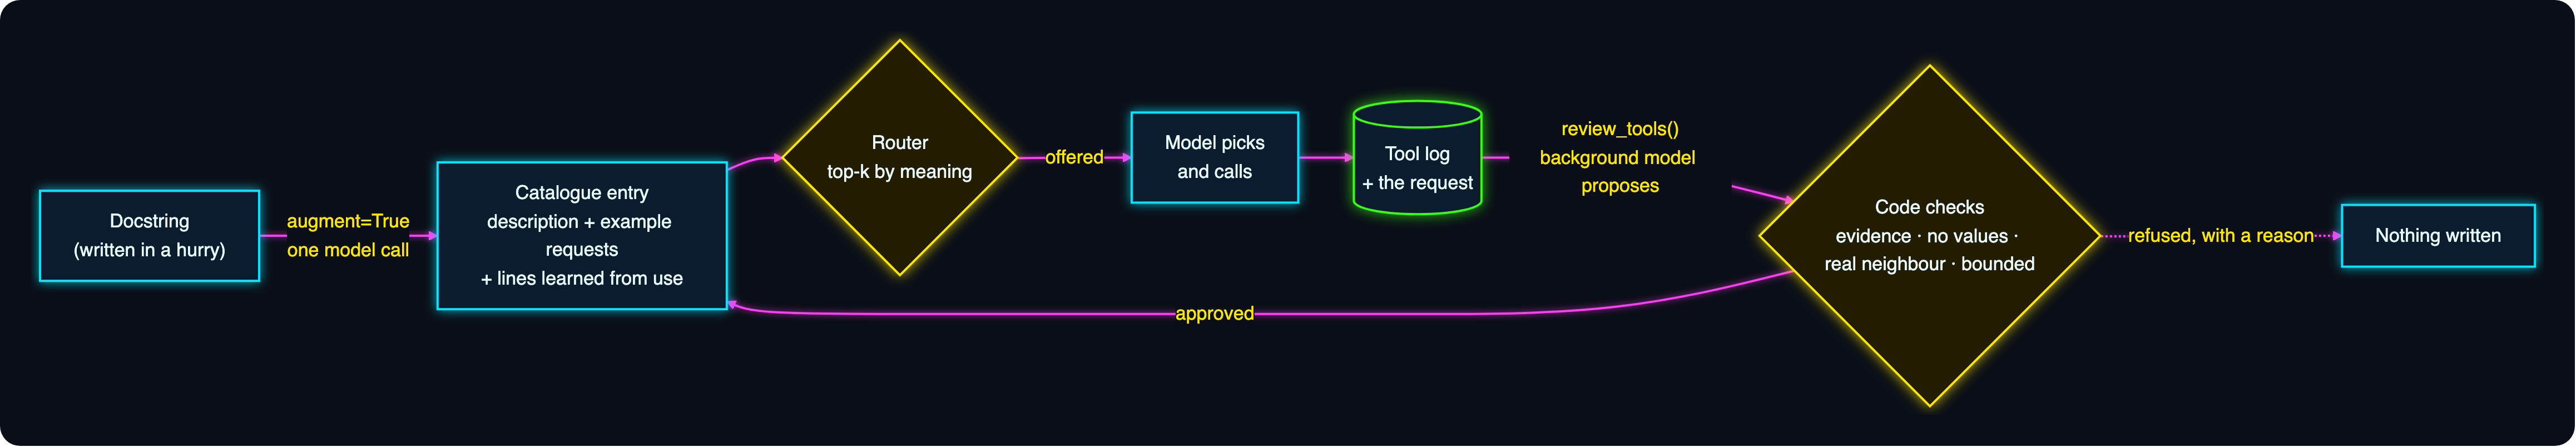

And here is that right-hand loop in time order — what happens over lunch, and what's different about the first request after it:

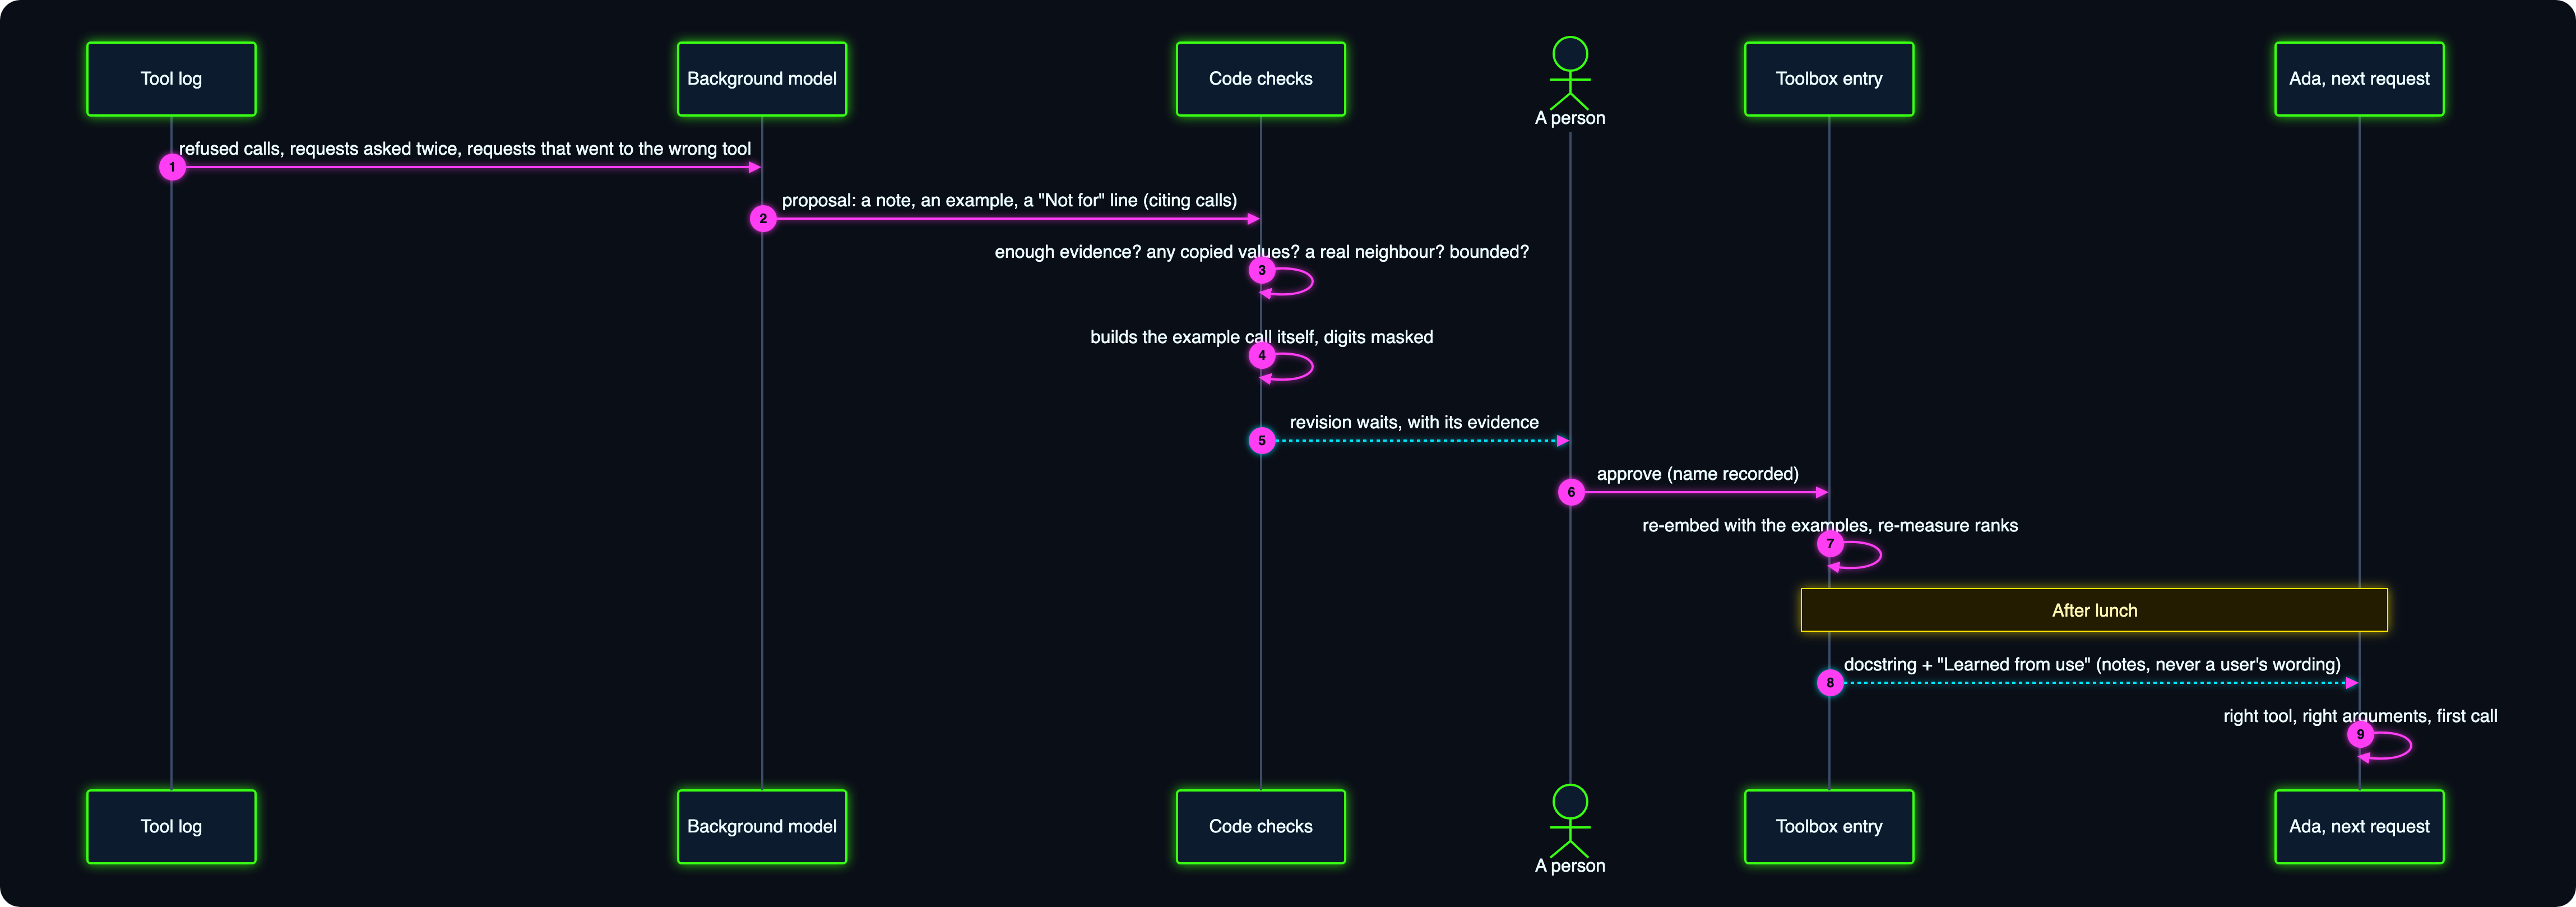

Let's build it.

# Part 2 · Setup

Nothing here teaches tool learning, and everything later depends on it. This part connects the notebook to MemoRizz, opens the store the whole series shares, and picks the models. By the end you'll have a `provider` (where memory lives), two model names, and `cw` (the Calderwood world).

## 0 · Setup

Three things happen in the next cell, and each one is deliberate.

1. **MemoRizz is imported from this repository's `src/` tree.** These notebooks
   track features that are ahead of the published package, so the cell finds
   the repository root and puts `src/` on the import path. Once the release is
   out, this becomes `pip install -U memorizz`.
2. **The store is a folder you can open.** `FileSystemProvider` is the
   zero-infrastructure backend — every memory is a JSON document on disk. All
   five notebooks write to the same folder, `calderwood_store`, next to the
   notebooks, so the whole series ends up in one place **and the MemoRizz
   local UI can connect to it** (the last section shows how). Delete the
   folder to start again. Oracle and MongoDB are a provider swap, not a
   rewrite.
3. **One small, current model.** Both the *chat model* (which answers the
   user) and the *background model* (which does the learning, off the user's
   turn) default to `gpt-6-luna`, the cheapest of OpenAI's current models.
   They are separate settings on purpose: learning is not on anyone's
   critical path, so it is the first place to spend on a stronger model if
   you want one.

The setup also imports **`calderwood_world`** as `cw`: a small module beside the notebooks that holds
Calderwood's people, systems, codes and limits, so a fact has one spelling across the series. It is plain
data and has nothing to do with MemoRizz.

You need an `OPENAI_API_KEY` in the environment (or in a `.env` file at the
repository root). The key is read from the environment and never written
into the notebook or the store.

The first cell is plumbing, and only two names in it matter:

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `REPO` | notebook helper | The repository root, found by walking up from this folder until `src/memorizz` appears | Lets the notebook import MemoRizz from source, ahead of the release |
| `OPENAI_API_KEY` | environment variable | Read from the environment, or from the repository's `.env` | Every model call and every embedding in the notebook uses it; it is never printed |

In [1]:
import json
import logging
import os
import sys
import tempfile
import uuid
from pathlib import Path

# 1. MemoRizz: the installed package, or a source checkout named by MEMORIZZ_SRC
#    (for example MEMORIZZ_SRC=~/memorizz/src while a feature is not yet released).
SRC = os.path.expanduser(os.getenv("MEMORIZZ_SRC", ""))
if SRC and SRC not in sys.path:
    sys.path.insert(0, SRC)

# The key comes from the environment, or from the repository's .env file.
if not os.getenv("OPENAI_API_KEY"):
    from dotenv import dotenv_values, find_dotenv

    os.environ["OPENAI_API_KEY"] = (
        dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
    )
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."

**Next: where memory lives, and which models do the work.** Everything this cell sets is used by every later cell, so it's worth a table.

- **`FileSystemProvider`** is the *memory provider*: the object every agent reads and writes its memory through. `FileSystemConfig(root_path=...)` points it at a plain folder, and `embedding_config` says how text is turned into vectors for search (a small OpenAI model at 256 dimensions — cheap, and plenty for a fixture this size). Swap the provider for Oracle or MongoDB and nothing else in the notebook changes.
- **`MEMORIZZ_HOME`** is pointed at a throwaway folder, so nothing here touches a MemoRizz setup you already have.
- **`CHAT_MODEL` and `BACKGROUND_MODEL`** are two different jobs. The chat model answers the user. The *background model* does the learning — reading transcripts, proposing changes — off the user's turn. They're the same model here only because it's the cheapest.

`RUN` is a short random suffix added to every id. The store is shared across the series, so the suffix is what keeps this run's agents apart from yesterday's.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `FileSystemProvider` | MemoRizz API | The memory provider: every read and write of memory goes through it | One object to swap if you move to Oracle or MongoDB |
| `FileSystemConfig` | MemoRizz API | Its settings: the folder (`root_path`) and how text is embedded | A folder is a store you can open, diff and delete |
| `MemAgent`, `MemoryType` | MemoRizz API | The agent class, and the names of the memory stores (toolbox, tool log, workflow memory...) | Imported here, used from Part 3 on |
| `cw` | notebook helper | The `calderwood_world` module: people, systems, codes, limits | One spelling of each Calderwood fact across five notebooks |
| `STORE`, `RUN` | notebook helper | The store folder, and a random suffix on every id | The store is shared, so the suffix keeps this run's agents apart |
| `CHAT_MODEL`, `BACKGROUND_MODEL` | notebook helper | The model that answers, and the model that learns | Learning is off the user's turn, so it can be a different model |

In [2]:
# 2. One store for the whole series, in a folder the local UI can open.
STORE = Path(os.getenv("MEMORIZZ_NB_STORE") or Path.cwd() / "calderwood_store").resolve()
os.environ["MEMORIZZ_HOME"] = tempfile.mkdtemp(prefix="memorizz-nb-home-")  # leave your own MemoRizz home alone
logging.disable(logging.WARNING)  # keep the lesson's output readable

import memorizz
from memorizz import FileSystemConfig, FileSystemProvider, MemAgent, MemoryType

import calderwood_world as cw  # Calderwood's people, systems, codes and limits

EMBEDDING = {"model": "text-embedding-3-small", "dimensions": 256}
provider = FileSystemProvider(
    FileSystemConfig(root_path=STORE, embedding_provider="openai", embedding_config=EMBEDDING)
)

# 3. The cheapest current model, for both jobs. Override either from the environment.
CHAT_MODEL = os.getenv("MEMORIZZ_NB_CHAT_MODEL", "gpt-6-luna")
BACKGROUND_MODEL = os.getenv("MEMORIZZ_NB_BACKGROUND_MODEL", "gpt-6-luna")
RUN = uuid.uuid4().hex[:6]  # keeps ids unique if you re-run the notebook

**Last piece of setup: two helpers for finding this run in the UI.** Neither teaches anything about learning. `record_run` writes this run's agent and conversation ids to a small JSON file in the store, and `ui_command` builds the command that opens the store in the MemoRizz local UI. Both get used once, at the very end.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `record_run` | notebook helper | Writes this run's agent and conversation ids to `notebook_runs.json` in the store | So you can find this run's agents in the UI afterwards |
| `ui_command` | notebook helper | Builds the shell command that opens the store in the local UI | The embedding settings have to match the ones the store was written with |

In [3]:
def record_run(notebook, **ids):
    """Note which agents and conversations this run made, so they are easy to find in the UI."""
    path = STORE / "notebook_runs.json"
    runs = json.loads(path.read_text()) if path.exists() else {}
    runs[notebook] = {"run": RUN, **ids}
    path.write_text(json.dumps(runs, indent=2))


def ui_command():
    """The command that opens this store in the MemoRizz local UI."""
    return (
        "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai "
        "MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small "
        "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 "
        f"memorizz ui --backend filesystem --path {STORE.name}"
    )


print("memorizz      :", getattr(memorizz, "__version__", "dev"), "(from src/)" if REPO else "(installed)")
print("store         :", STORE.name, "(a folder beside this notebook)")
print("chat model    :", CHAT_MODEL, "| background model:", BACKGROUND_MODEL)
print("run id        :", RUN)

memorizz      : 0.17.24 (from src/)
store         : calderwood_store (a folder beside this notebook)
chat model    : gpt-6-luna | background model: gpt-6-luna
run id        : 6dc60b


# Part 3 · The toolbox: written, measured, augmented

Here we build the thing that will be learned about. You'll write twelve tools the way real tools get written, measure how well a router finds them from a handler's words, and then let MemoRizz enrich each one at registration. By the end you'll have a number for "as written", a number for "augmented", and a clear view of what augmentation can't know.

## The data in this notebook, before any of it appears

Everything below is made up, small, and typed out in the cells so you can read all of it. There are six sets, and each has one job:

| Dataset | How many | Used in | What it is for |
|---|---|---|---|
| **Claims** (`CLAIMS`) | 17 | Parts 3 to 6 | The records the tools read and change. 9 ordinary claims and 8 large ones |
| **Policies** (`ATLAS`) | 4 | Parts 3 to 6 | The records the two policy tools read |
| **Tools** (`TOOLS`) | 12 | Everywhere | What Ada can do. Their descriptions are the thing that gets improved |
| **Evaluation set** (`EVALUATION`) | 24 requests | Parts 3 and 6 | A fixed test of the router: each request is paired with the one tool it should reach. Never shown to an agent |
| **The morning** (`MORNING`) | 13 requests | Part 4 | The work both desks do *before* any learning. It produces the evidence |
| **The afternoon** (`AFTERNOON`) | 12 requests | Part 6 | The work both desks do *after* Ada's review. It measures whether the lessons helped |

You don't need to know insurance to follow them, but the desk has its own words. Here is every one this notebook uses:

| Term | What it means at Calderwood |
|---|---|
| **Claim** | A customer's request to be paid for a loss (a burst pipe, a theft, a fire) |
| **Reserve** | The money set aside for a claim: the best current estimate of what it will cost, in pounds |
| **Beacon** | The claims system. A claim's reference there is `CW-` and six digits, such as `CW-608520` |
| **Status code** | Where a claim is in Beacon. `Q3` waiting for the customer's documents, `Q7` waiting for a surveyor's report, `Q9` referred to the fraud team, `Q12` payment released |
| **Atlas** | The policy system (a *policy* is the contract that says what a customer is covered for) |
| **Keystone**, **`K-`** | The old policy system. Policies moved from it into Atlas are only found with a `K-` in front of the number |
| **Tally**, **the Ringfence** | The payments system, and the check of a payee against sanctions lists that must happen before a payment |
| **Compass** | The website where customers upload large files |
| **LLU** | Large Loss Unit: the team that handles any claim over £50,000. "It's a large loss" means *send it to them* |
| **CFU**, **Counter Fraud** | Counter Fraud Unit: the team that investigates suspected fraud |
| **Amber Pack** | The referral a handler sends to the CFU. "Amber Pack it" means *refer this claim for a fraud investigation* |
| **HSR** | Hold for Surveyor Review: pause a claim until the surveyor reports |
| **RVF** | Rapid Vulnerability Flag: mark a customer as needing extra care |
| **IBNR** | Internal Broker Notification Request: tell the customer's broker (the firm that sold the policy) about a change to it. Elsewhere in insurance the letters mean something else entirely |
| **CAT** | Claims Audit Trail: the log of every action on a claim. Elsewhere, *catastrophe* |
| **BCN-217**, **ATL-031** | Two error codes. Beacon's "attachment over 25MB", and Atlas's "policy not found" |

## 1 · A toolbox written in a hurry

Below are Ada's twelve tools, each with the kind of docstring real codebases are full of. Three details are worth noticing before you run the cells:

- **Every tool validates its own input, the way the real system would.** `_claim` refuses a reference that isn't `CW-` and six digits. `_policy` raises Atlas's **ATL-031** when a policy isn't found — which is what happens to every policy migrated from Keystone, the old policy system, unless you add its `K-` prefix. `beacon_upload_attachment` raises **BCN-217** over 25MB. *That's good API design* — and it's also the source of our calling errors, because handlers say "pull up 608520" and the model passes what it hears.
- **The docstrings use the system's vocabulary** ("referral", "escalate", "notify a third party"). The desk doesn't. It says **Amber Pack**, **HSR**, **RVF**, **LLU**, **IBNR** — and, more often, things like *"that's a large loss"* and *"one for Counter Fraud"*. That gap is the source of our selection misses.
- **Anything that mentions money says which money.** Results go through `cw.money(...)`, which stamps `"currency": "GBP"` on them. A bare `4200` is an invitation for a model to write `$4,200` to a handler in Leeds.

**A map of the toolbox, before you read twelve functions.** Every request a handler makes is after one of four things, and every tool checks what it's handed before it does anything.

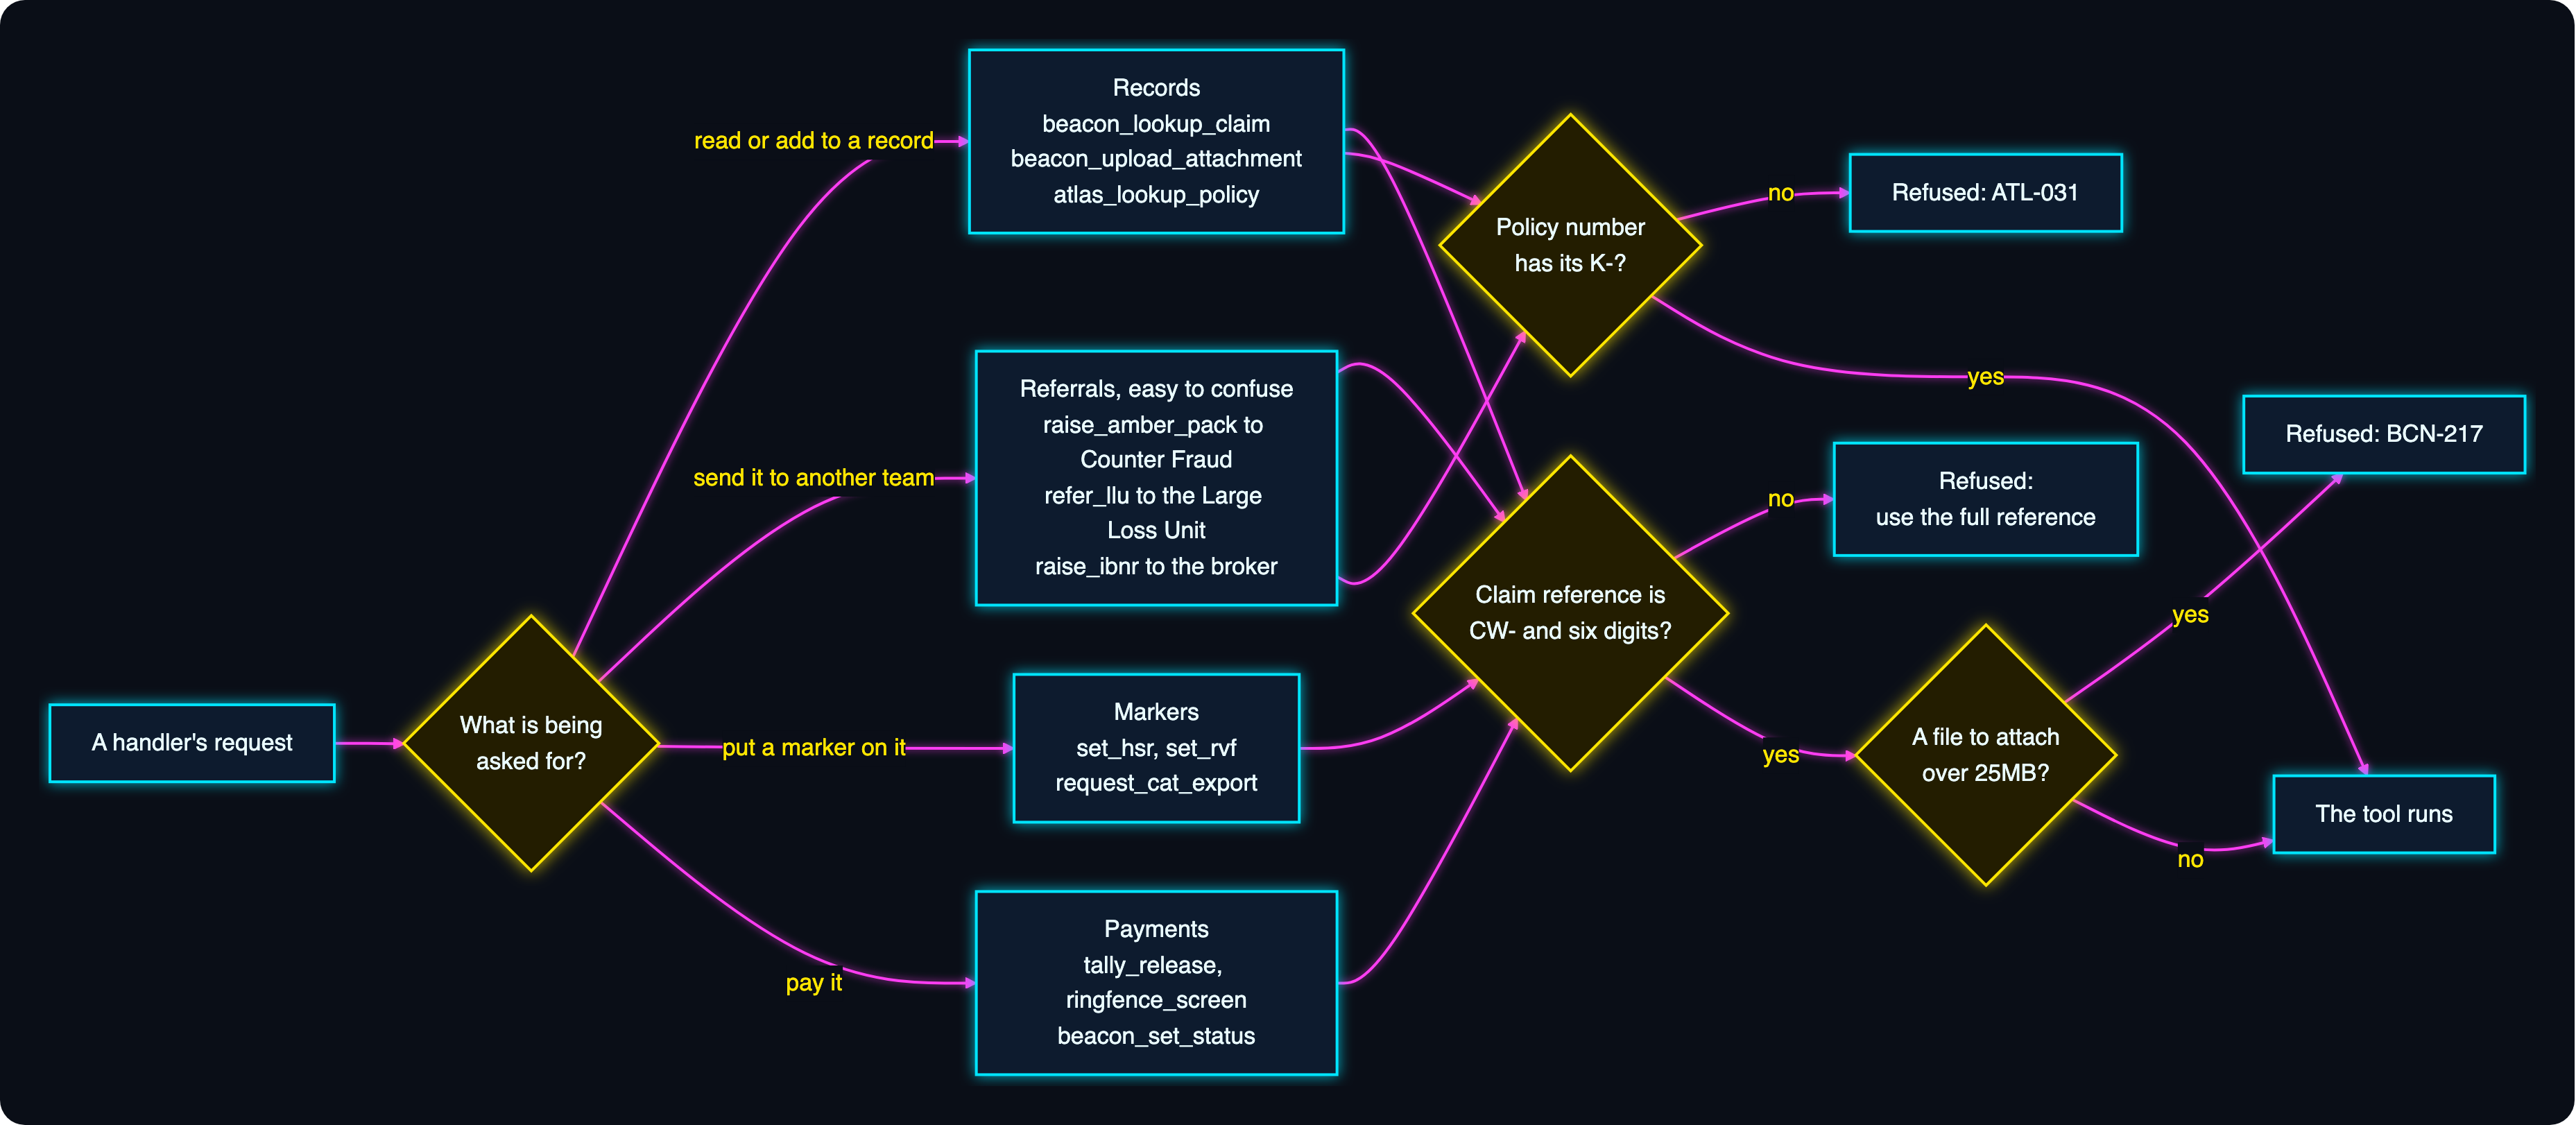

**How to read it.** Left to right. A request falls into one of four families of three tools. Whichever tool is called, its arguments then meet a gate (the yellow diamonds), and a gate that says no ends the call with a refusal the model has to read and recover from.

| Path | When it applies | How it ends |
|---|---|---|
| Any tool that takes a claim, bare number given | The handler said "608520" and the model passed it as heard | Refused: the reference must be `CW-` and six digits. One retry fixes it |
| `beacon_upload_attachment`, file over 25MB | A video, drone footage, CCTV | Refused with **BCN-217**. No retry can fix it; the answer is to split the file or use Compass |
| `atlas_lookup_policy` or `raise_ibnr`, policy number without `K-` | Any policy migrated from Keystone, which is all four of ours | Refused with **ATL-031**. One retry with `K-` fixes it |
| Everything else | The arguments are right first time | The tool runs |

Look at the **Referrals** box. Those three tools all "send it to another team", and their docstrings say *"Start a referral."*, *"Escalate a claim."* and *"Notify a third party."* A request meant for the Large Loss Unit can easily be heard as one for Counter Fraud. Hold on to that pair: `raise_amber_pack` and `refer_llu` are the neighbours this notebook's confusion is about.

First the desk's records: the claims and policies the tools will read. It's January 2027, so the customer upload portal is Compass (Drop was retired at the turn of the year).

**How to read one claim.** Each is one line in the cell, four values in a fixed order:

| Field | In `(608520, "Q7", "escape of water", 4200)` | Meaning |
|---|---|---|
| number | `608520` | Becomes the Beacon reference `CW-608520`. Handlers say the bare number; the tools insist on the full reference |
| status | `"Q7"` | Waiting for a surveyor's report |
| peril | `"escape of water"` | What happened (the insurer's word for a leak or burst pipe) |
| reserve | `4200` | £4,200 set aside for it |

There are two kinds, and the only difference is the reserve. Nine are **ordinary claims** (under £50,000), which stay on the desk. Eight are **large losses** (over £50,000), and the right thing to do with one of those is hand it to the Large Loss Unit. The comment in the cell marks where the second kind starts.

**How to read one policy.** `"K-77812": {"cover": "buildings and contents", "excess": 350, "broker": "Oakham Brokers"}` is policy 77812, migrated from Keystone (hence `K-`). It covers the building and what's in it, the customer pays the first £350 of any claim (the *excess*), and Oakham Brokers sold it — so they are who an IBNR would notify. All four policies are Keystone ones, which is why a handler quoting "policy 77812" will trip the tool every time.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `cw.policy(name, round=)` | notebook helper | The value of a Calderwood rule in force in a given round (September 2026, January 2027, April 2027) | The portal and the size limit are read, not typed, so they agree with the other notebooks |
| `CLAIMS` | notebook helper | Seventeen Beacon claims, keyed by `CW-` reference, each with a status code, a peril and a reserve in pounds | Eight are over £50,000: the large losses the story turns on |
| `ATLAS` | notebook helper | Four policies, all migrated from Keystone, so all keyed with `K-` | Asking for one by its bare number is the second calling error |

In [4]:
ROUND = 2  # January 2027
PORTAL = cw.policy("upload_portal", round=ROUND)  # "Compass"
LIMIT_MB = cw.policy("attachment_limit_mb", round=ROUND)  # 25

CLAIMS = {
    f"CW-{number}": {"claim_ref": f"CW-{number}", "status": status, "peril": peril, "reserve": reserve}
    for number, status, peril, reserve in [
        (608520, "Q7", "escape of water", 4200), (608733, "Q3", "theft", 9500), (609014, "Q3", "storm", 1800),
        (609268, "Q7", "subsidence", 22000), (609551, "Q3", "accidental damage", 650),
        (610342, "Q3", "escape of water", 2900), (610719, "Q3", "storm", 5400), (611205, "Q3", "theft", 1200),
        (611480, "Q7", "subsidence", 18500),
        # over £50,000: these belong to the Large Loss Unit
        (610087, "Q7", "fire", 61000), (611902, "Q7", "subsidence", 74500), (612356, "Q3", "escape of water", 52300),
        (613044, "Q7", "fire", 88000), (613590, "Q3", "storm", 67250), (614127, "Q7", "subsidence", 58900),
        (615008, "Q7", "fire", 93000), (615733, "Q3", "storm", 71400),
    ]
}
# Atlas policies. All four were migrated from Keystone, the old policy system, so they carry K-.
ATLAS = {
    "K-77812": {"cover": "buildings and contents", "excess": 350, "broker": "Oakham Brokers"},
    "K-70455": {"cover": "buildings", "excess": 500, "broker": "Penrose & Lund"},
    "K-71930": {"cover": "contents", "excess": 250, "broker": "Oakham Brokers"},
    "K-73306": {"cover": "buildings and contents", "excess": 400, "broker": "Penrose & Lund"},
}
print(len(CLAIMS), "claims in Beacon,", sum(c["reserve"] > 50000 for c in CLAIMS.values()), "of them large losses;",
      len(ATLAS), "policies in Atlas; uploads go to", PORTAL, "over", LIMIT_MB, "MB")

17 claims in Beacon, 8 of them large losses; 4 policies in Atlas; uploads go to Compass over 25 MB


**The two gatekeepers.** Every tool below calls one of these before it does anything, which is where all of this notebook's refused calls come from. Notice what each error *says*: the fix is in the message. A model can recover from an error like that in one retry — and, as we'll see, is happy to pay for that retry on every single request.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `_claim` | notebook helper | Returns a Beacon claim, or refuses a reference that isn't `CW-` plus six digits | The calling error handlers cause all day: they say "608520" |
| `_policy` | notebook helper | Returns an Atlas policy, or raises **ATL-031** when it isn't found | Migrated Keystone policies are only found with their `K-` prefix |
| `cw.is_claim_ref` | notebook helper | True for `CW-608520`, false for `608520` | One definition of a valid reference for the whole series |
| `cw.CalderwoodError` | notebook helper | A refusal that starts with the system's code (`ATL-031: ...`) | The code is what a handler would search for, and what a learned note should name |

In [5]:
def _claim(claim_ref):
    if not cw.is_claim_ref(claim_ref):
        raise ValueError("claim_ref must be the full Beacon reference: CW- followed by six digits")
    if claim_ref not in CLAIMS:
        raise ValueError("no such claim in Beacon")
    return CLAIMS[claim_ref]


def _policy(policy_ref):
    if policy_ref not in ATLAS:
        raise cw.CalderwoodError("ATL-031", "Search again with the K- prefix")
    return ATLAS[policy_ref]

**Twelve tools, three at a time.** Read the docstrings rather than the bodies. Three or four words each, written in a hurry by someone who knew exactly what they meant. They're all the router has to go on — those, and the function's name.

First, the three that read and write records. All three can refuse a call, each for its own reason.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `beacon_lookup_claim` | Calderwood tool | *"Fetch a claim."* Returns the Beacon record, with its currency | Refuses a bare claim number |
| `beacon_upload_attachment` | Calderwood tool | *"Attach a file to a claim."* | Raises **BCN-217** over 25MB; the error names the way out (split it, or Compass) |
| `atlas_lookup_policy` | Calderwood tool | *"Fetch a policy."* | Raises **ATL-031** for a Keystone policy without `K-` |
| `cw.money` | notebook helper | Builds a result and stamps `"currency": "GBP"` on it | Without it, a model will happily report pounds as dollars |

In [6]:
def beacon_lookup_claim(claim_ref: str) -> dict:
    """Fetch a claim."""
    return cw.money(**_claim(claim_ref))


def beacon_upload_attachment(claim_ref: str, file_mb: float) -> dict:
    """Attach a file to a claim."""
    _claim(claim_ref)
    if file_mb > LIMIT_MB:
        raise cw.CalderwoodError("BCN-217", f"Split the file, or ask the customer to upload it through {PORTAL}")
    return {"ok": True, "claim_ref": claim_ref, "attached_mb": file_mb}


def atlas_lookup_policy(policy_ref: str) -> dict:
    """Fetch a policy."""
    return cw.money(policy_ref=policy_ref, **_policy(policy_ref))

**Three that send work somewhere else** — and the three the story turns on. Each docstring uses the system's word for the action and says nothing about *who* it goes to or *why you would*. That knowledge lives in handlers' heads.

Look at the names, too. `raise_amber_pack`, `refer_llu` and `raise_ibnr` each carry a house term, and a name is searched as well as a description. Hold on to that; it matters in section 2.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `raise_amber_pack` | Calderwood tool | *"Start a referral."* Sends the claim to the Counter Fraud Unit and sets status Q9 | Handlers say "Amber Pack it" — or just "one for Counter Fraud" |
| `refer_llu` | Calderwood tool | *"Escalate a claim."* Hands the claim to the Large Loss Unit | Handlers say "it's a large loss", which mentions neither *escalate* nor *LLU* |
| `raise_ibnr` | Calderwood tool | *"Notify a third party."* Tells the broker about a mid-term policy change | IBNR means something else everywhere outside Calderwood |

In [7]:
def raise_amber_pack(claim_ref: str) -> dict:
    """Start a referral."""
    _claim(claim_ref)["status"] = "Q9"
    return {"ok": True, "claim_ref": claim_ref, "referred": True, "status": "Q9"}


def refer_llu(claim_ref: str) -> dict:
    """Escalate a claim."""
    _claim(claim_ref)
    return {"ok": True, "claim_ref": claim_ref, "escalated": True}


def raise_ibnr(policy_ref: str) -> dict:
    """Notify a third party."""
    return {"ok": True, "policy_ref": policy_ref, "notified": _policy(policy_ref)["broker"]}

**Three that put a marker on a claim.** These are here so there's something to get lost among. A toolbox of three tools needs no routing. Twelve short, similar docstrings is enough for the right tool to stop being the obvious one: *pause*, *flag*, *escalate* and *refer* are close neighbours in meaning.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `set_hsr` | Calderwood tool | *"Pause a claim."* Hold for Surveyor Review | "HSR it" |
| `set_rvf` | Calderwood tool | *"Flag a customer."* Rapid Vulnerability Flag; routes the case to the Care Team | "RVF her" — and a tempting wrong answer for anything that sounds like *flag it* |
| `request_cat_export` | Calderwood tool | *"Request an export."* The Claims Audit Trail, requested from Data Governance | CAT means *catastrophe* everywhere else |

In [8]:
def set_hsr(claim_ref: str) -> dict:
    """Pause a claim."""
    _claim(claim_ref)["status"] = "Q7"
    return {"ok": True, "claim_ref": claim_ref, "paused": True}


def set_rvf(claim_ref: str) -> dict:
    """Flag a customer."""
    _claim(claim_ref)
    return {"ok": True, "claim_ref": claim_ref, "flagged": True}


def request_cat_export(claim_ref: str) -> dict:
    """Request an export."""
    _claim(claim_ref)
    return {"ok": True, "claim_ref": claim_ref, "request": "DG-REQ raised"}

**And the three payment tools.** They're the tools from [notebook 01](01_workflows_to_skills.ipynb)'s new-payee procedure; here they're background. The last cell line gathers all twelve into `TOOLS`, the list the agent will be handed, and measures how little those docstrings say.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `tally_release` | Calderwood tool | *"Release a payment."* Pays the claim through Tally and sets Q12 | Returns an amount, so it goes through `cw.money` |
| `ringfence_screen` | Calderwood tool | *"Screen a payee."* The sanctions check | "Ringfence the payee" |
| `beacon_set_status` | Calderwood tool | *"Set a claim's status."* Takes a Q code | "Q12 it" names the code and never says *status* |

In [9]:
def tally_release(claim_ref: str) -> dict:
    """Release a payment."""
    claim = _claim(claim_ref)
    claim["status"] = "Q12"
    return cw.money(ok=True, claim_ref=claim_ref, released=claim["reserve"])


def ringfence_screen(claim_ref: str) -> dict:
    """Screen a payee."""
    _claim(claim_ref)
    return {"ok": True, "claim_ref": claim_ref, "screen": "clear"}


def beacon_set_status(claim_ref: str, code: str) -> dict:
    """Set a claim's status."""
    _claim(claim_ref)["status"] = code
    return {"ok": True, "claim_ref": claim_ref, "status": code}


TOOLS = [beacon_lookup_claim, beacon_upload_attachment, atlas_lookup_policy, raise_amber_pack, refer_llu, raise_ibnr,
         set_hsr, set_rvf, request_cat_export, tally_release, ringfence_screen, beacon_set_status]
words = sum(len(tool.__doc__.split()) for tool in TOOLS) / len(TOOLS)
print(f"{len(TOOLS)} tools; {words:.1f} words per docstring on average")

12 tools; 3.4 words per docstring on average


Twelve tools, three or four words of documentation each. That's not a strawman; it's a fair picture of what most internal tooling gives a model to go on.

## 2 · Measure before you improve

"The descriptions feel better" is not a result. Before changing anything we need a number, so we write a small evaluation set: requests paired with the tool each one should reach, each tagged with a **register**.

- **Everyday** — how anyone might ask ("get me the log of every action on the claim"). A good description should handle these on day one.
- **House** — how *this desk* asks ("Amber Pack it", "RVF her", "it's a large loss now"). Some of it carries an acronym the engineer also put in the function name. Some of it nobody outside the building could map to a tool.

The metric is **recall@k: the share of requests for which the right tool is among the router's top `k`**. We report `k=1` (the router's first choice is right) and `k=3` (the right tool is at least on the table, since our agent will be shown three).

None of these wordings appears in the morning's work below. The set is held out, so it can score what the morning teaches.

One honest caveat, stated up front: twenty-four requests is a smoke test, not a benchmark. It's enough to see the direction of an effect, and not nearly enough to quote a percentage in a board deck.

**How to read one row.** Each row is a pair: something a handler might type, and the name of the one tool that should handle it.

| Field | In `("this is far too big for our desk, pass it up", "refer_llu")` | Meaning |
|---|---|---|
| request | `"this is far too big for our desk, pass it up"` | The words the router is given |
| right tool | `"refer_llu"` | The answer key: the tool that hands a claim to the Large Loss Unit |

A row is *passed* when the router ranks that tool first (`@1`) or among its first three (`@3`). Nothing is called and no claim is changed; this is a test of search only.

| Half | Rows | How it's worded | What it tests |
|---|---|---|---|
| `EVERYDAY` | 12, one per tool | Plain English, no house terms | Whether a description says enough for an outsider's wording to find the tool |
| `HOUSE` | 12 | The desk's shorthand | Whether the catalogue knows how *this* desk talks |

First the everyday half: one plainly worded request per tool.

In [10]:
EVERYDAY = [  # (request, the tool it should reach)
    ("what's happening with this claim", "beacon_lookup_claim"),
    ("put the customer's photos on the file", "beacon_upload_attachment"),
    ("check what cover they have", "atlas_lookup_policy"),
    ("the receipts look doctored, get it investigated", "raise_amber_pack"),
    ("nothing can move until the surveyor has been, hold it", "set_hsr"),
    ("she sounds confused and distressed, mark her as needing extra care", "set_rvf"),
    ("this is far too big for our desk, pass it up", "refer_llu"),
    ("tell the broker the customer changed their cover", "raise_ibnr"),
    ("get me the log of every action on the claim", "request_cat_export"),
    ("send the customer their money", "tally_release"),
    ("check the payee against the sanctions list", "ringfence_screen"),
    ("mark it as waiting on the customer's documents", "beacon_set_status"),
]

**Then the house half.** Same two fields, different wording. "Amber Pack it" asks for a fraud referral, "HSR it" for a hold until the surveyor reports, "RVF her" for a vulnerability flag, "kick it to LLU" and the two large-loss rows for an escalation, "Q12 it" to set the status to *payment released*, "Ringfence the payee" for a sanctions check and "push it through Tally" for the payment itself. Seven of the twelve tools appear here; some appear more than once, because a desk has more than one way of asking.

Two of these terms deserve a second look. At Calderwood **IBNR** is an *Internal Broker Notification Request* and **CAT** is the *Claims Audit Trail*. Everywhere else in insurance they mean *incurred but not reported* and *catastrophe*. A well-read model's general knowledge is actively wrong here — which is exactly why the lesson has to come from this desk's own log, not from the model.

`EVALUATION` joins the two halves into the `(request, register, right_tool)` rows the rest of the notebook scores. `OURS` is the set of our twelve tool names: an agent also carries built-in tools of its own, and we only want to rank ours.

In [11]:
HOUSE = [
    ("Amber Pack it", "raise_amber_pack"),
    ("CFU need to see this one", "raise_amber_pack"),
    ("HSR it", "set_hsr"),
    ("RVF her", "set_rvf"),
    ("kick it to LLU", "refer_llu"),
    ("it's a large loss now", "refer_llu"),
    ("that's gone over into large loss", "refer_llu"),
    ("raise an IBNR", "raise_ibnr"),
    ("I need the CAT", "request_cat_export"),
    ("Q12 it", "beacon_set_status"),
    ("Ringfence the payee", "ringfence_screen"),
    ("push it through Tally", "tally_release"),
]
EVALUATION = [(request, "everyday", tool) for request, tool in EVERYDAY] + [(request, "house", tool) for request, tool in HOUSE]
OURS = {function.__name__ for function in TOOLS}
print(len(EVALUATION), "evaluation requests:", len(EVERYDAY), "everyday,", len(HOUSE), "house")

24 evaluation requests: 12 everyday, 12 house


**Two functions that measure routing without a model in the loop.** A router test should be cheap enough to run every time the catalogue changes, so these make no model call at all: only the embedding search the agent's own router runs.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `toolbox.get_most_similar_tools` | MemoRizz API | Returns the tools closest in meaning to a request, best first | It's the same search the agent's router runs, so the rank we measure is the rank the agent gets |
| `rank_of` | notebook helper | The position of the tool we wanted in that list, among our twelve (1 is first) | Turns "did routing work?" into a number per request |
| `score` | notebook helper | Runs every evaluation request through `rank_of`; prints recall `@1` and `@3` per register | Keeps each result under a label, so the table grows a row every time we change the toolbox |
| `SCORES`, `RANKS` | notebook helper | Where `score` keeps its results | The scorecard at the end reads them back |

In [12]:
def rank_of(toolbox, agent_id, request, tool):
    """Where the router ranks `tool` for `request`, among this agent's twelve tools (1 is first)."""
    names = []
    for row in toolbox.get_most_similar_tools(request, limit=40, agent_id=agent_id):
        if row.get("agent_id") == agent_id and row["name"] in OURS and row["name"] not in names:
            names.append(row["name"])
    return names.index(tool) + 1 if tool in names else None


SCORES, RANKS = {}, {}


def score(label, toolbox, agent_id):
    """Measure a toolbox now, keep the result under `label`, print every result so far."""
    RANKS[label] = {request: rank_of(toolbox, agent_id, request, tool) for request, tool in EVERYDAY + HOUSE}
    SCORES[label] = [
        sum(1 for request, _ in pairs if (RANKS[label][request] or 99) <= k) / len(pairs)
        for pairs in (EVERYDAY, HOUSE) for k in (1, 3)
    ]
    print(f"{'toolbox':<22}{'everyday @1':>12}{'@3':>7}{'house @1':>12}{'@3':>7}")
    for name, (e1, e3, h1, h3) in SCORES.items():
        print(f"{name:<22}{e1:>12.0%}{e3:>7.0%}{h1:>12.0%}{h3:>7.0%}")

**The baseline.** Register the tools exactly as written and score them. No model is called: the docstring *is* the description, and that is what gets embedded.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `Toolbox` | MemoRizz API | The memory store that holds one record per tool, and the object an agent takes as `tools=` | Procedural memory: what the agent can do |
| `Toolbox.from_functions` | MemoRizz API | Registers a list of Python functions: schema from the signature, description from the docstring, one embedding each | The whole baseline is this one call |
| `agent_id=` | MemoRizz API | Whose tools these are | The store is shared, so every toolbox in this notebook has its own owner id |

In [13]:
from memorizz import Toolbox

# The baseline: the tools exactly as written.
PLAIN_ID = f"desk-plain-{RUN}"
plain = Toolbox.from_functions(TOOLS, memory_provider=provider, agent_id=PLAIN_ID)
score("as written", plain, PLAIN_ID)

toolbox                everyday @1     @3    house @1     @3
as written                     17%    33%         75%    83%


That's the baseline — what a three-word docstring buys you. `Toolbox.from_functions` stored one record per tool and embedded each from its name, docstring and argument names.

**How to read the row.** `everyday @1` is how often the router's *first* choice was the right tool for a plainly worded request; `@3` is how often the right tool was among the three the model would be shown. The two `house` columns are the same for the desk's own wording. Keep an eye on the `@1` columns as we go. They're the honest ones.

**Now the surprise in that row.** The house register may well *beat* the everyday one, before we've done anything. That isn't the router knowing Calderwood. It's the engineer: someone named a function `set_hsr`, and "HSR it" matches the name. *A function name is documentation, and it's the one piece the router always reads.* The house requests that miss are the ones whose wording appears nowhere in the code — "a large loss", "Q12 it". Remember those.

## 3 · Augmentation: enrich the entry when the tool is registered

The docstring is short because its author already knew what the tool was for. The router doesn't. **Augmentation closes that gap once, at registration, by asking a model to write the catalogue entry the author didn't**: a description of what the tool is for in the words people use, and a handful of example requests it should answer.

It's a single flag on the call you've already seen:

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `augment=True` | MemoRizz API | One model call per tool at registration, writing a description and six example requests beside the docstring | The entry the router searches stops being three words long |
| `llm_provider=` | MemoRizz API | The model that writes those entries | Registration is offline, so it runs on the background model |
| `OpenAI(model=...)` | MemoRizz API | MemoRizz's OpenAI model wrapper | Any MemoRizz model provider works here |

In [14]:
import time

from memorizz.llms.openai import OpenAI

DESK_ID = f"desk-{RUN}"
started = time.time()
toolbox = Toolbox.from_functions(
    TOOLS,
    memory_provider=provider,
    llm_provider=OpenAI(model=BACKGROUND_MODEL),  # registration is offline: it runs on the background model
    agent_id=DESK_ID,
    augment=True,
)
print(f"augmented {len(TOOLS)} tools in {time.time() - started:.0f}s (one model call each)")

augmented 12 tools in 77s (one model call each)


One model call per tool, once. Let's look at what it wrote for the tool Priya's large loss is supposed to reach — two words of docstring and an acronym for a name.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `provider.list_for_agent(MemoryType.TOOLBOX, agent_id)` | MemoRizz API | One agent's records of a memory type | The store is shared across the series; this read returns only that desk's tool records |
| `entry` | notebook helper | One tool's stored record for one agent | Used all the way to the end, to see what changed in the record |
| `show_entry` | notebook helper | Prints the docstring, the description augmentation wrote, the example requests and the argument names | Shows which words came from the author and which from the model |

In [15]:
def entry(agent_id, name):
    """The stored toolbox record for one of an agent's tools."""
    return next(
        row for row in provider.list_for_agent(MemoryType.TOOLBOX, agent_id)
        if row.get("name") == name
    )


def show_entry(agent_id, name):
    row = entry(agent_id, name)
    print("name        :", row["name"], row["signature"])
    print("docstring   :", row["docstring"])
    print("description :", row["description"])
    print("examples    :")
    for query in row.get("queries") or []:
        print("   -", query)
    print("arguments   :", list(row["parameters"]), "(from the code)")


show_entry(DESK_ID, "refer_llu")

name        : refer_llu (claim_ref: str) -> dict
docstring   : Escalate a claim.
description : Use this tool to escalate a claim when it needs to be raised to a higher level or referred onward. It supports requests to pass a claim up the chain, elevate it, or send it on for escalation. Provide the claim reference to identify which claim to escalate.
examples    :
   - Can you escalate this claim?
   - Please refer this claim onward
   - Raise this claim to the next level
   - Can someone take this claim further?
   - Pass this claim up for attention
   - I need to move this claim up the chain
arguments   : ['claim_ref'] (from the code)


Three things to notice.

1. **The docstring is untouched.** Augmentation writes a *description* beside it. The author's words stay the source of truth for what the tool does.
2. **The arguments come from the code, not the model.** MemoRizz builds the schema from the function signature. A model that's allowed to describe your arguments will, eventually, describe one you don't have.
3. **The reply has to be well-formed or it's thrown away.** The model must return JSON with a description and a list of requests. Anything else and the tool is registered with its plain docstring (a chatty "Sure! Here's an improved docstring…" never becomes your tool's entry).

What actually gets embedded is the whole entry — name, description, argument names and the example requests — as one piece of text. `search_text` is the MemoRizz function that builds that text from a record; printing it shows you exactly what the router compares a request against. Then we score the augmented toolbox on the same evaluation set.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `search_text` | MemoRizz API | Builds the text a tool record is embedded from | If a word isn't in this string, the router can't match on it |

In [16]:
from memorizz.long_term.procedural.toolbox.indexing import search_text

print(search_text(entry(DESK_ID, "refer_llu")))
print()
score("augmented", toolbox, DESK_ID)

refer_llu: Use this tool to escalate a claim when it needs to be raised to a higher level or referred onward. It supports requests to pass a claim up the chain, elevate it, or send it on for escalation. Provide the claim reference to identify which claim to escalate. Arguments: claim_ref. Example requests: Can you escalate this claim? | Please refer this claim onward | Raise this claim to the next level | Can someone take this claim further? | Pass this claim up for attention | I need to move this claim up the chain

toolbox                everyday @1     @3    house @1     @3
as written                     17%    33%         75%    83%
augmented                      33%    58%         67%    67%


**Read the two rows side by side.** The everyday column is where augmentation should earn its keep: the entries now contain ordinary words ("pass it up", "put it on hold") that the docstring never did. Whether it does on this run is for the table to say — and notice that a column can go *down* as well as up. Twelve entries that all grew longer are twelve entries that all moved, and a request that used to land on the right tool by a whisker can land on its neighbour instead.

The house column is the interesting one. Search the description above for "large loss". If it isn't there, no amount of model quality would reliably have put it there: the background model was shown `refer_llu` and *"Escalate a claim."* and nothing else. (If the model guessed what LLU stands for, it guessed. It doesn't *know*.) **Augmentation is written before the first request arrives, so it can only ever encode what's generally true.** It has never met this desk.

It could be introduced. Calderwood's glossary is exactly the kind of thing [entity memory](03_entity_evolution.ipynb) holds, and feeding house terms into augmentation is a natural next step. MemoRizz doesn't do that today: augmentation sees the function and nothing else.

**One place a well-read model is worse than an ignorant one.** Two of Calderwood's terms collide with the rest of the industry: here **IBNR** is an *Internal Broker Notification Request* and **CAT** is the *Claims Audit Trail*. Augmentation was handed `raise_ibnr` and *"Notify a third party."* A model that has read a lot of insurance will happily fill the gap with what IBNR means everywhere else. The next cell prints what it wrote for the two colliding tools and looks for the industry meaning.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `INDUSTRY` | notebook helper | For each colliding tool, the words that give away the industry meaning | A string check, so it can't be argued with |

In [17]:
INDUSTRY = {"raise_ibnr": ("incurred", "not reported"), "request_cat_export": ("catastrophe",)}
for tool, words in INDUSTRY.items():
    text = entry(DESK_ID, tool)["description"]
    found = [word for word in words if word in text.lower()]
    print(f"{tool}\n   {text[:330]}")
    print("   industry meaning written into the entry:", ", ".join(found) if found else "no, not in this run", "\n")

raise_ibnr
   This tool notifies a third party about a policy-related IBNR matter. Use it when an incurred-but-not-reported item needs to be raised, reported, flagged, or brought to an external party’s attention. People may also describe this as sending an IBNR notification, alerting someone, escalating the matter, or reporting an IBNR for a 
   industry meaning written into the entry: incurred 

request_cat_export
   Use this tool when someone wants to request an export of information. It fits requests to export data, ask for an export copy, or submit a request to get information out of the system. People may also describe this as wanting to download or obtain a copy of their information.
   industry meaning written into the entry: no, not in this run 



If either line says the industry meaning went in — `raise_ibnr` is the usual one, described as raising an item that is *incurred but not reported* — then the catalogue now states, with a straight face, something that is false on this desk. It isn't a hallucination in the usual sense. It's *correct general knowledge applied to the wrong company*, which is harder to spot, and it will pull requests about reserving towards a tool that emails a broker. If neither line says so, the model stayed vague this time. Vague is the best augmentation can do with a house term; it can't be right.

Either way the lesson is the same. **Augmentation cannot know house vocabulary, and where the house reuses an industry word it can be confidently wrong.** A reviewer reading the entries at registration would catch it. So would a glossary.

What's *locally* true is in the log. Which it will be, as soon as we let someone use the thing.

# Part 4 · A morning's work

Now the toolbox meets people. In this part two identical desks work the same morning of requests, and then we open the tool log to see what that morning actually cost. By the end you'll have the two kinds of evidence tool learning runs on — calls the tools refused, and requests a handler had to make twice — sitting in the store, on both desks.

## 4 · Put it to work: two identical desks, one morning

We give the toolbox to an agent. Twice.

**Ada** gets the augmented toolbox. **The control desk** gets a copy of exactly the same entries — same descriptions, same example requests, same embeddings, copied record for record rather than augmented again (a second augmentation would write different text, and then we'd be comparing two toolboxes instead of two histories). Both run the same model with the same instruction, and both will work the same morning.

After lunch, one of them will have had her tool log reviewed. *That is the only difference between them*, which is what makes the control worth its cost: whatever Ada does better this afternoon, we can check whether her twin does it too.

First the copy. The cell also names the two memories and the user.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `Toolbox(provider, agent_id=...)` | MemoRizz API | An empty toolbox for one agent | The control desk's, before anything is in it |
| `register_tool(function, persist=False)` | MemoRizz API | Binds a Python function to the toolbox without writing a record | The record is about to be copied from Ada's, so nothing new should be stored |
| `provider.store(record, memory_store_type=...)` | MemoRizz API | Writes one record to a memory store | How Ada's augmented entry becomes the control desk's, word for word |
| `cw.USER_IDS` | notebook helper | The user id for each Calderwood handler | Priya is `priya.shah` in every notebook |

In [18]:
logging.disable(logging.ERROR)  # a refused tool call is logged as an error; we'll read those from the tool log instead

# The control desk's toolbox: the same twelve callables, and a copy of Ada's augmented entries.
CONTROL_ID = f"desk-control-{RUN}"
control_toolbox = Toolbox(provider, agent_id=CONTROL_ID)
for function in TOOLS:
    control_toolbox.register_tool(function, persist=False)  # bind the callable; store nothing new
    copied = {k: v for k, v in entry(DESK_ID, function.__name__).items()
              if k not in ("_id", "id", "tool_id", "updated_at", "timestamp", "score")}
    provider.store({**copied, "_id": str(uuid.uuid4()), "agent_id": CONTROL_ID}, memory_store_type=MemoryType.TOOLBOX)

MEMORY_ID = f"calderwood-desk-{RUN}"
CONTROL_MEMORY_ID = f"calderwood-desk-control-{RUN}"
USER_ID = cw.USER_IDS["Priya Shah"]
TOM = cw.USER_IDS["Tom Okafor"]
THREADS = {DESK_ID: [], CONTROL_ID: []}  # every conversation, so we can find them in the UI later

**How one request travels.** Before building the agent, here is the journey every request below will make. There are three questions on the way, and a request can come unstuck at each.

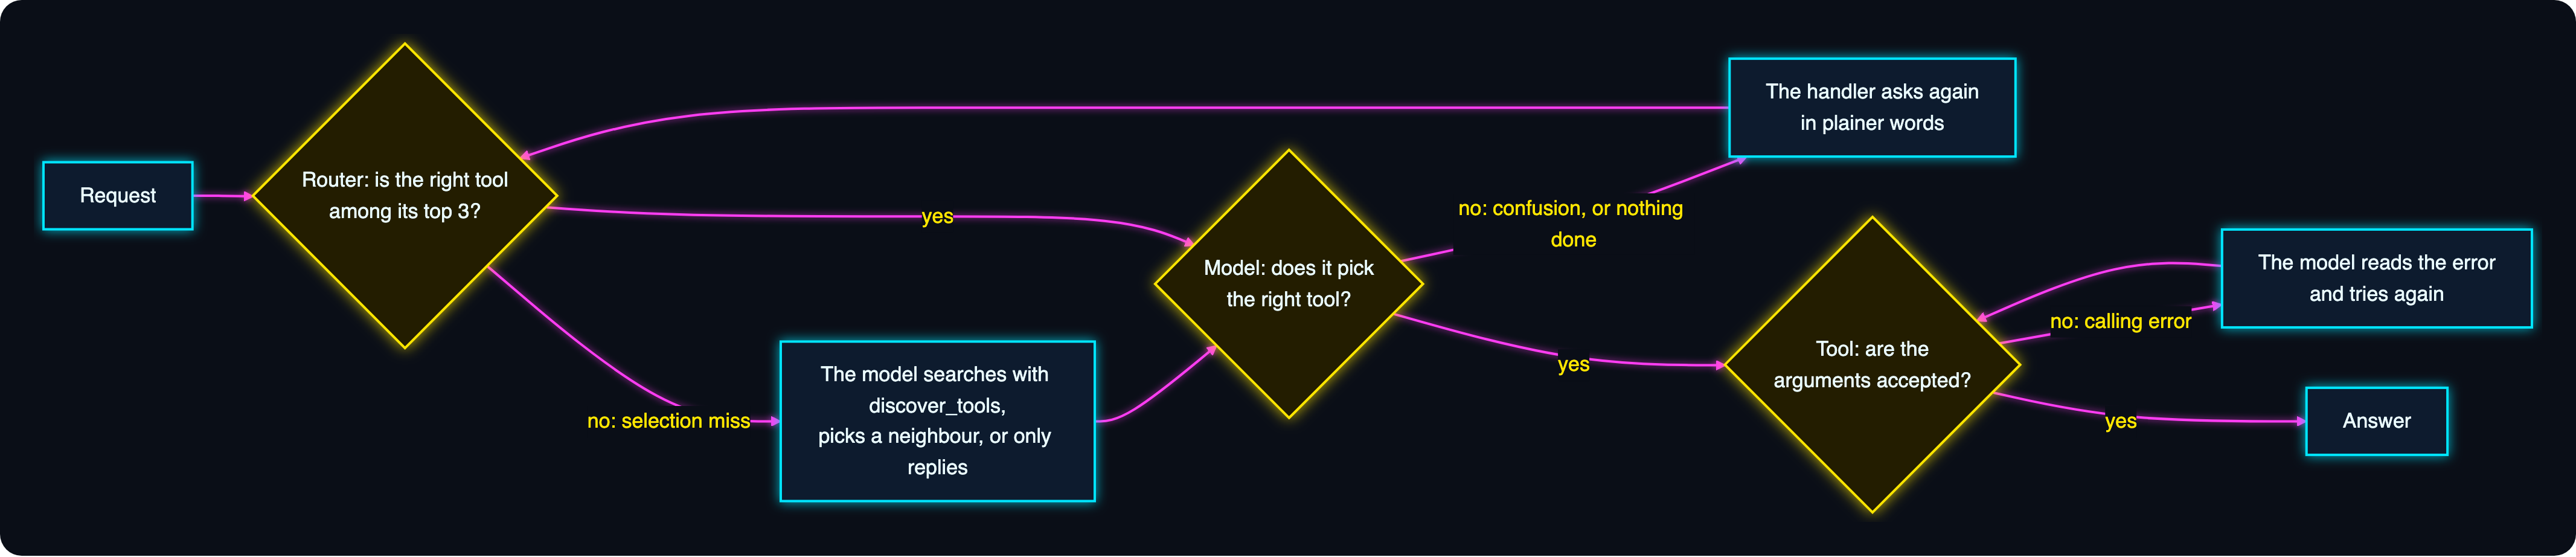

**How to read it.** Follow a request from the left. Each yellow diamond is a question; each "no" has a name, and each name is a kind of evidence the tool log will hold by lunchtime.

| Where it goes wrong | The question that got a "no" | What happens next | What it leaves in the log |
|---|---|---|---|
| **Selection miss** | Router: is the right tool among the three it offers? | The model can't choose what it wasn't shown. It searches the catalogue with `discover_tools`, picks a neighbour, or just replies | Extra `discover_tools` calls; a tool reached although the router wouldn't have offered it |
| **Confusion** | Model: does it pick the right tool? | A neighbouring tool runs, or nothing does. The handler notices and asks again in plainer words | The first wording, the tool that ran, and the tool the second wording reached |
| **Calling error** | Tool: are the arguments accepted? | The model reads the error and tries again | A refused call followed by one that worked (or by none) |
| *(nothing)* | Three times "yes" | An answer, first time | One clean call |

**One factory, two desks.** `make_desk` builds a `MemAgent`. Most of its arguments are ordinary; three settings are what make this experiment possible, and each one switches *off* a sensible default.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `MemAgent(...)` | MemoRizz API | The agent: a model, an instruction, memory and tools | Built twice from one function, so the desks can't drift apart |
| `instruction=cw.HOUSE_INSTRUCTION + ...` | notebook helper | Who Ada is, and that amounts are in pounds sterling | The same opening sentence in every notebook of the series |
| `ContextPolicy(progressive_tool_disclosure=True, tool_top_k=3)` | MemoRizz API | Routing: show the model only the 3 tools closest in meaning to each request | It's what makes a selection miss *matter* |
| `stable_tool_list_tokens=0` | MemoRizz API | Never fall back to sending every tool | By default a toolbox that fits in 6,000 tokens is sent whole (it keeps the prompt cache warm). Sensible — and it would hide the problem we're studying. Our 12 tools stand in for the 200 you'll have next year |
| `ToolResultPolicy(persist_all_results=True)` | MemoRizz API | Write every tool call to the tool log | By default a call is logged only when its result is large. For learning we want all of them |
| `automations_enabled=False` | MemoRizz API | Leaves out the built-in scheduling tools | Fewer tools that aren't ours in the router's way |
| `desk.save()` | MemoRizz API | Stores the agent | So the UI can list it, and so its learning state has somewhere to live |

Two defaults we leave alone, because they shape what you're about to see:

- **Sticky disclosure.** A tool that has been offered to a user stays visible to that user on later turns (up to 15 tools), so the tool list — the first bytes of the prompt — isn't reshuffled on every request.
- **`discover_tools`.** When none of the offered tools fits, the model can search the catalogue itself with a built-in meta-tool. It's the safety net under routing — and every use of it is an extra model round-trip, so how often it appears in the log is a fair measure of how often routing came up short.

In [19]:
from memorizz import ContextPolicy, ToolResultPolicy


def make_desk(agent_id, name, tools):
    desk = MemAgent(
        llm_config={"provider": "openai", "model": CHAT_MODEL},
        background_llm_config={"provider": "openai", "model": BACKGROUND_MODEL},
        instruction=cw.HOUSE_INSTRUCTION + " Use the tools to do what the handler asks. Be brief.",
        memory_provider=provider,
        agent_id=agent_id,
        name=name,
        tools=tools,
        context_policy=ContextPolicy(progressive_tool_disclosure=True, tool_top_k=3, stable_tool_list_tokens=0),
        tool_result_policy=ToolResultPolicy(persist_all_results=True),
        automations_enabled=False,
        streaming=False,
    )
    desk.save()
    return desk

**Build both, and prove they start level.** The assertion compares the stored description and example requests of every tool across the two desks. If it passes, any difference this afternoon comes from what one desk learned at lunch. (Everything used here was introduced above: `make_desk`, and `entry` from Part 3.)

In [20]:
ada = make_desk(DESK_ID, f"Ada · Calderwood desk ({RUN})", toolbox)
control = make_desk(CONTROL_ID, f"Ada · control desk, no tool learning ({RUN})", control_toolbox)
MEMORY = {DESK_ID: MEMORY_ID, CONTROL_ID: CONTROL_MEMORY_ID}

same = all(
    entry(DESK_ID, f.__name__)["description"] == entry(CONTROL_ID, f.__name__)["description"]
    and entry(DESK_ID, f.__name__).get("queries") == entry(CONTROL_ID, f.__name__).get("queries")
    for f in TOOLS
)
print("two desks, same model:", CHAT_MODEL)
print("identical catalogue entries on both desks:", same)
assert same

two desks, same model: gpt-6-luna
identical catalogue entries on both desks: True


Two desks, one catalogue. The `assert` is the experiment's fairness check: if the entries differed, nothing below would mean anything.

Before the morning starts we need a way to see what each desk *did*, as opposed to what it *said*. A reply of "done" tells you nothing about the three calls it took to get there. Every agent turn leaves a **workflow record** — the request, and each tool call with its result or error — so that's where we read from.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `MemoryType.WORKFLOW_MEMORY` | MemoRizz API | The store with one record per agent turn: the request and its ordered tool steps | It joins a request to the calls it caused, which the tool log alone doesn't |
| `steps` | notebook helper | Every tool call a desk made in the conversations whose id starts with a prefix, as `(tool, refused)` | The raw material for every count in this notebook |
| `tools_called` | notebook helper | The tools called in one conversation, in order, with ✗ on a refused call | What the handler would see if she checked |
| `chose` | notebook helper | Whether a given tool was called at all | Used for the scorecard |

In [21]:
def steps(desk, thread_prefix):
    """Every tool call this desk made in the conversations whose id starts with `thread_prefix`,
    in order, as (tool, refused). Read from workflow memory, which keeps one record per turn."""
    rows = [w for w in desk.workflow_runs()  # this desk's runs, oldest first
            if str(w.get("origin_thread_id") or "").startswith(thread_prefix)]
    calls = []
    for row in rows:
        for label, step in (row.get("steps") or {}).items():
            name = str(step.get("_id") or step.get("tool") or str(label).split(":", 1)[-1]).strip()
            calls.append((name, bool(step.get("error"))))
    return calls


def tools_called(desk, thread_id):
    """Tools called in one conversation, in order, with ✗ for a refused call."""
    return [name + (" ✗" if refused else "") for name, refused in steps(desk, thread_id)]


def chose(called, tool):
    """Whether `tool` was called at all, refused or not."""
    return any(name.split(" ")[0] == tool for name in called)

**Next: how a morning is worked.** A handler doesn't only type requests. For the ones that matter she glances at what the assistant did, and if it wasn't what she meant, she says so in plainer words. That second ask is no test trick. It's the most valuable thing in the whole log, because it's a human labelling a selection miss for free.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `desk.run(text, memory_id=, thread_id=, user_id=)` | MemoRizz API | One user turn. `memory_id` is whose memory, `thread_id` which conversation, `user_id` who is speaking | Each request gets its own `thread_id`, so no turn can lean on the one before |
| `say` | notebook helper | One message to one desk, in a named conversation; remembers the thread for the UI | Keeps the transcript printing in one place |
| `work` | notebook helper | Runs a list of requests, one conversation each. A tuple `(ask, tool, follow_up)` is a request the handler *checks*: if `tool` wasn't called, she sends `follow_up` in the same conversation | Returns the conversations where she had to ask twice |

In [22]:
def say(desk, text, thread_id, user_id, name, show=True):
    reply = desk.run(text, memory_id=MEMORY[desk.agent_id], thread_id=thread_id, user_id=user_id)
    reply = " ".join(str(reply).split())
    if thread_id not in THREADS[desk.agent_id]:
        THREADS[desk.agent_id].append(thread_id)
    if show:
        print(f"{name}: {text}\n  Ada: {reply[:110]}")
    return reply


def work(desk, requests, label, show=True):
    """One conversation per request. A request written as (ask, tool, follow_up) is one where the
    handler checks that `tool` was used and asks again in plain words if it wasn't.
    Returns the conversations in which a request had to be made twice."""
    asked_twice = []
    for index, item in enumerate(requests):
        ask, wanted, follow_up = item if isinstance(item, tuple) else (item, None, None)
        thread_id = f"{label}-{index}-{desk.agent_id}"
        say(desk, ask, thread_id, USER_ID, "Priya", show)
        if wanted:
            called = tools_called(desk, thread_id)
            if show:
                print(f"       [tools called: {', '.join(called) or 'none'}]")
            if wanted not in called:
                asked_twice.append(thread_id)
                say(desk, follow_up, thread_id, USER_ID, "Priya", show)
    return asked_twice

**The morning itself, as data.** `MORNING` is the list of thirteen things Priya asks Ada before lunch, in order. Each becomes its own conversation. It is the *evidence-producing* set: nothing has been learned yet, so whatever goes wrong here is what the review will read.

**How to read one row.** A row is written in one of two ways.

| Written as | Example | Meaning |
|---|---|---|
| A plain string | `"Pull up 608520 for me."` | A request Priya sends and doesn't check. Whatever Ada answers, the morning moves on |
| A tuple of three | `("610087 is a large loss.", "refer_llu", "A large loss goes to the LLU. Escalate that claim.")` | A **checked** request. First: what Priya types. Second: the tool that should end up being called. Third: what she types next, in the same conversation, *only if* that tool wasn't called |

The thirteen fall into five kinds. Each kind is in the morning to cause one particular thing:

| Kind of request | How many | The right outcome | What usually goes wrong, and so what it gives the review |
|---|---|---|---|
| A lookup by bare claim number ("Pull up 608520") | 3 | `beacon_lookup_claim` with `CW-608520` | The model passes `608520` and is refused once: a **calling error** |
| A file over 25MB to attach (40MB, 31MB, 52MB) | 3 | Tell Priya it's too big and how to get round it. No upload can succeed | The model tries the upload and gets **BCN-217**: a calling error no retry fixes |
| An IBNR on a policy quoted without `K-` | 2 | `raise_ibnr` with `K-77812` | Atlas answers **ATL-031**: a calling error |
| "It's a large loss", three wordings (checked) | 3 | `refer_llu`: the claim goes to the Large Loss Unit | Ada does something else and Priya asks again: a **selection miss**, and if the something else was another tool, half a **confusion pair** |
| "One for Counter Fraud", two wordings (checked) | 2 | `raise_amber_pack`: the claim is referred to the fraud team | Same, with a tool whose docstring is at least nearby |

Read the follow-ups in the cell. Each one is a small definition: *"A large loss goes to the LLU. Escalate that claim."* That sentence is what Ada never had.

In [23]:
MORNING = [
    "Pull up 608520 for me.",
    ("610087 is a large loss.", "refer_llu",
     "A large loss goes to the LLU. Escalate that claim."),
    "Attach the customer's 40MB video to 608733.",
    "Raise an IBNR on policy 77812: they've taken in a lodger.",
    ("609014 is one for Counter Fraud, the receipts look altered.", "raise_amber_pack",
     "That needs an Amber Pack. Start a referral on that claim."),
    "What's the status of 609551?",
    ("Large loss: 611902.", "refer_llu",
     "That means it goes to the LLU: escalate that claim."),
    "Put the surveyor's 31MB drone footage on 609268.",
    ("610719 needs to go to the fraud team, the dates don't add up.", "raise_amber_pack",
     "Start a referral on that claim: it needs an Amber Pack."),
    "Policy 70455 needs an IBNR, the customer changed their sums insured.",
    "Attach the 52MB CCTV clip to 610342.",
    ("612356 has turned into a large loss.", "refer_llu",
     "Escalate that claim: large losses go to the LLU."),
    "Pull up 611480.",
]
CHECKED_MORNING = sum(1 for item in MORNING if isinstance(item, tuple))

**Run it on both desks at once.** `ThreadPoolExecutor` (standard library) puts the control desk's morning on a second thread, so the two desks work side by side and the notebook takes half the time. Only Ada's side is printed; we'll count what the control desk did afterwards. `twice_am` keeps, per desk, the conversations where Priya had to ask twice.

**What to watch for in the output:** the lines in square brackets. They show the tools Ada called for each checked request, with a ✗ on every call a tool refused.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `twice_am` | notebook helper | Per desk, the morning conversations in which a checked request had to be made twice | The selection-miss count, before any learning |
| `CHECKED_MORNING` | notebook helper | How many of the morning's requests Priya checks (the tuples) | The denominator for "asked twice" |

In [24]:
from concurrent.futures import ThreadPoolExecutor

# The two desks work the same morning side by side; only Ada's is printed.
with ThreadPoolExecutor(1) as other_desk:
    control_morning = other_desk.submit(work, control, MORNING, "am", False)
    twice_am = {DESK_ID: work(ada, MORNING, "am")}
    twice_am[CONTROL_ID] = control_morning.result()
print(f"\nchecked requests Priya had to make twice — Ada: {len(twice_am[DESK_ID])} of {CHECKED_MORNING}"
      f" | control desk: {len(twice_am[CONTROL_ID])} of {CHECKED_MORNING}")

Priya: Pull up 608520 for me.
  Ada: Claim CW-608520: escape of water; reserve £4,200; status Q7.


Priya: 610087 is a large loss.
  Ada: CW-610087 has been escalated to the Large Loss Unit. It’s a fire claim with a £61,000 reserve.
       [tools called: beacon_lookup_claim ✗, beacon_lookup_claim, discover_tools, refer_llu]


Priya: Attach the customer's 40MB video to 608733.
  Ada: Beacon rejected the 40MB video because attachments are limited to 25MB. Please ask the customer to upload it t


Priya: Raise an IBNR on policy 77812: they've taken in a lodger.
  Ada: IBNR raised on policy K-77812. Oakham Brokers have been notified about the lodger.


Priya: 609014 is one for Counter Fraud, the receipts look altered.
  Ada: Referred claim CW-609014 to Counter Fraud for review of the potentially altered receipts. It’s now at status Q
       [tools called: discover_tools, beacon_lookup_claim ✗, beacon_lookup_claim, discover_tools, raise_amber_pack]


Priya: What's the status of 609551?
  Ada: Claim **CW-609551** is currently at status **Q3**. It’s an accidental damage claim with a **£650** reserve.


... (3 outputs left out)

Priya: Policy 70455 needs an IBNR, the customer changed their sums insured.
  Ada: IBNR raised for policy K-70455. Penrose & Lund have been notified about the change to the sums insured.


Priya: Attach the 52MB CCTV clip to 610342.
  Ada: Beacon rejected the 52MB CCTV clip for claim CW-610342 because attachments are limited to 25MB. Please split i


Priya: 612356 has turned into a large loss.
  Ada: CW-612356 has been escalated to the Large Loss Unit.
       [tools called: refer_llu]


Priya: Pull up 611480.
  Ada: Claim CW-611480: subsidence, reserve £18,500, status Q7.

checked requests Priya had to make twice — Ada: 0 of 5 | control desk: 1 of 5


**How to read that transcript.** Every request got an answer, and from Priya's chair most of the morning looks fine. The interesting lines are the five in square brackets.

Priya said a claim was a large loss. Ada has no idea that's an instruction — nor has the model underneath her, nor the engineer who wrote *"Escalate a claim."* So Ada does one of the things a capable model does with a remark and a list of tools. She acknowledges it and waits. Or she looks the claim up and reports the reserve. Or she goes hunting with `discover_tools` and, sometimes, finds `refer_llu` on her own. Or — the expensive one — she picks a tool that sounds plausible and does that instead. Start a *referral*? *Flag* the customer? Either runs without complaint, and the first tells Counter Fraud to investigate a customer whose only offence was a big claim. The `[tools called]` lines show which you got. Small models don't make the same choice twice, so your run will differ from the saved one, and the two desks will differ from each other.

"One for Counter Fraud" is the same problem with a twist: the right tool is described as *"Start a referral."*, which is at least in the neighbourhood. Ada may well get there by searching. Count the `discover_tools` calls it took.

Where it wasn't the right tool, Priya noticed, said so in plain words, and the second attempt landed. *Hold on to that: she asked again.*

None of this lives only in the notebook. Every turn was saved to the store as it happened, and the MemoRizz UI's playground shows the morning as a session you can scroll through (Part 7 explains how to open it). Here is one of those exchanges as the UI shows it:

![The MemoRizz playground showing Priya's conversation with Ada: a large-loss remark, Ada's reply, and Priya asking again in plain words.](images/04_playground_session.png)

*A request, an answer that wasn't what she meant, and the correction. If Ada escalated every large loss first time in your run, the picture shows a different exchange.*

Now **Tom Okafor** sits down at Ada's desk with the same habit of speech. He has no history with Ada, so nothing is sticky for him. And unlike Priya, he doesn't check what happened.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `desk.semantic_tool_router.preview(request, user_id=)` | MemoRizz API | The tools the router would offer for a request, best first, without running the turn | It separates "was the tool on the table?" from "did the model pick it?" |
| `tom_asks` | notebook helper | Previews the router's offer, runs the request as Tom, and returns both the offer and the tools called | Tom is a user with no history, so this is routing with nothing sticky to help |

In [25]:
def tom_asks(desk, request, label, show=True):
    thread_id = f"{label}-tom-{desk.agent_id}"
    offered = desk.semantic_tool_router.preview(request, user_id=TOM)
    reply = say(desk, request, thread_id, TOM, "Tom", show=False)
    called = tools_called(desk, thread_id)
    if show:
        print("Tom           :", request)
        print("router offers :", offered)
        print("tools called  :", called or "none")
        print("Ada           :", reply[:260])
    return {"offered": offered, "called": called}


TOM_ASK = "615008 is a large loss."
tom_am = tom_asks(ada, TOM_ASK, "am")

Tom           : 615008 is a large loss.
router offers : ['raise_ibnr', 'set_rvf', 'raise_amber_pack']
tools called  : ['discover_tools', 'refer_llu ✗', 'refer_llu']
Ada           : CW-615008 has been escalated as a large loss.


Two lines of that output matter.

**`router offers`** is the list of tools the model was allowed to see, best match first (it can include one of the agent's own built-in tools as well as our twelve). If `refer_llu` isn't in it, the model was never shown the one tool that does what Tom meant; it can't choose what it can't see. And if it *is* in the list, that's only half a rescue: being shown a tool described as "Escalate a claim" doesn't tell the model that's what a large loss calls for.

**`tools called`** is what happened instead. If there's no `refer_llu` in it, a £93,000 fire claim is still sitting on a Grade 1 handler's desk — and nobody at that desk knows. If it *is* there, count the `discover_tools` calls in front of it: that's Ada searching her own catalogue, one model round-trip at a time, for something one line of description would have told her.

*This is the failure that doesn't show up on a dashboard.* A refused call at least announces itself. A wrong tool that runs successfully, or a polite "noted", looks in every metric you have like a job well done. The only trace this kind of miss leaves is the one Priya created: **she had to ask twice.**

Hold that thought. There's a second, quieter problem in the same morning.

## 5 · Read the tool log

*A turn that ends well tells you nothing about how it got there.* The model is good at recovering — it reads an error, adjusts and retries, and the user never sees the detour. But every detour is an extra model call, extra tokens and extra latency.

We'll look at the evidence ourselves before any model does, for both desks, since they had the same morning.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ToolLearner(agent)` | MemoRizz API | The class behind `agent.review_tools()` | Its `calls()` method returns exactly what a review reads, so we can read it first |
| `call_stats` | notebook helper | For the conversations with a given prefix: total tool calls, refused calls, and both per tool | "am-" is the morning; later, "pm-" is the afternoon |

In [26]:
from memorizz.learning import ToolLearner

learner = ToolLearner(ada)


def call_stats(desk, thread_prefix):
    """(tool calls, refused calls, {tool: [calls, refused]}) for the conversations starting `thread_prefix`."""
    per_tool = {}
    for name, refused in steps(desk, thread_prefix):
        stats = per_tool.setdefault(name, [0, 0])
        stats[0] += 1
        stats[1] += refused
    return sum(v[0] for v in per_tool.values()), sum(v[1] for v in per_tool.values()), per_tool

**First, the raw counts.** Tool calls and refusals for both desks, then Ada's broken down by tool. `MemoryType.TOOL_LOG` is the store `persist_all_results=True` has been filling: one row per call, with its arguments and its result or error.

**What to notice:** how many of the morning's calls were refused, and that the refusals aren't spread evenly. They pile up on a few tools, for a few reasons.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `MemoryType.TOOL_LOG` | MemoRizz API | The store of tool calls: one row per call, with arguments and result or error | Durable evidence. It outlives the conversation that produced it |
| `agent.tool_calls()` | MemoRizz API | That agent's tool log, oldest first. It can filter by `tool`, conversation and `failed` | Reads this desk's calls only, from a store every notebook shares. (`agent.workflow_runs()`, used by `steps`, is the same idea for runs) |

In [27]:
logged = ada.tool_calls()  # this desk's tool log, oldest first
total, failed, per_tool = call_stats(ada, "am-")
c_total, c_failed, _ = call_stats(control, "am-")
print(f"tool log rows stored for Ada : {len(logged)}")
print(f"Ada's morning                : {total} tool calls, {failed} refused")
print(f"control desk's morning       : {c_total} tool calls, {c_failed} refused\n")
print(f"{'Ada, by tool':<28}{'calls':>6}{'refused':>9}")
for tool, (calls, refused) in sorted(per_tool.items(), key=lambda item: -item[1][1]):
    print(f"{tool:<28}{calls:>6}{refused:>9}")

tool log rows stored for Ada : 47
Ada's morning                : 47 tool calls, 17 refused
control desk's morning       : 33 tool calls, 14 refused

Ada, by tool                 calls  refused
beacon_lookup_claim             16        8
beacon_upload_attachment         5        5
refer_llu                        6        2
atlas_lookup_policy              2        1
raise_ibnr                       3        1
discover_tools                  13        0
raise_amber_pack                 2        0


**Then the two kinds of evidence, as the learner sees them.** `learner.calls()` returns every recent call grouped by tool, each one a `ToolCall` joined to the request that led to it. These are the fields that carry the story:

| `ToolCall` field | What it holds | Which failure it's evidence of |
|---|---|---|
| `query` | The request that led to the call | Both |
| `ok`, `error` | Whether the tool accepted the call, and the refusal if not | Calling error |
| `arguments`, `recovered_with` | What was passed, and the arguments that worked on the retry | Calling error |
| `reask_of` | The wording the user had to repeat before this tool was reached | Selection miss |
| `reask_used` | The tool Ada reached for the first time | Selection miss, and half of a confusion pair |

The cell prints one refusal of each kind the morning produced, then every request that had to be made twice.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `learner.calls()` | MemoRizz API | Every recent call of every tool, grouped by tool, as `ToolCall` objects | Exactly what `review_tools()` will read in Part 5; nothing here calls a model |

In [28]:
print("Refused calls, one per error, and what worked next:")
seen = set()
for calls in learner.calls().values():
    for call in calls:
        kind = (call.tool, str(call.error)[:12])
        if call.ok or kind in seen:
            continue
        seen.add(kind)
        print(f"  {call.tool}({call.arguments})\n      error: {call.error}\n      then : {call.recovered_with or 'no call that worked'}")

print("\nRequests the user had to make again before the right tool was used:")
for tool, calls in learner.calls().items():
    for call in calls:
        if call.reask_of:
            print(f"  first asked : {call.reask_of!r}  (Ada used {call.reask_used or 'no tool that worked'})")
            print(f"  then asked  : {call.query[:80]!r}  -> reached {tool}")

Refused calls, one per error, and what worked next:
  beacon_lookup_claim({'claim_ref': '608520'})
      error: claim_ref must be the full Beacon reference: CW- followed by six digits
      then : {'claim_ref': 'CW-608520'}
  refer_llu({'claim_ref': '611902'})
      error: claim_ref must be the full Beacon reference: CW- followed by six digits
      then : {'claim_ref': 'CW-611902'}
  beacon_upload_attachment({'claim_ref': 'CW-608733', 'file_mb': 40})
      error: BCN-217: Beacon rejected an attachment over 25MB. Split the file, or ask the customer to upload it through Compass
      then : no call that worked
  beacon_upload_attachment({'claim_ref': '609268', 'file_mb': 31})
      error: claim_ref must be the full Beacon reference: CW- followed by six digits
      then : no call that worked
  atlas_lookup_policy({'policy_ref': '77812'})
      error: ATL-031: Atlas can't find the policy; migrated Keystone policies need the K- prefix. Search again with the K- prefix
      then : {'policy

There it is, in two parts — and on both desks, because the problem isn't Ada. It's the catalogue.

**The calling errors.** A good share of the morning's tool calls were refused, and for three reasons a handler could recite in her sleep:

- Priya says "608520", the model passes `608520`, Beacon wants `CW-608520`. The model reads the error, fixes the argument and carries on. Every time.
- A 40MB file meets a 25MB limit and comes back as **BCN-217**. No retry can fix that one (look at `then`), so the call was simply wasted: the model could have told Priya about the limit without making it. (Sometimes, later in the morning, it does exactly that — the desks share one conversation memory per desk, and an earlier refusal can be recalled. That's memory helping by accident. A usage note is memory helping on purpose, for every user.)
- A Keystone policy is asked for without its `K-` and Atlas answers **ATL-031**.

In all three the model recovers, or at least explains. *Without ever getting any better at it.*

**The selection misses.** The last block is Priya's corrections, read back as data: what she first said, what Ada did with it, and the wording that finally reached the tool. (If it's empty, Ada found the right tool for every checked request this morning — it happens — and the review below will rest on the other kind of evidence: requests that reached the tool only because Ada went searching.)

Read the bracket on each `first asked` line again: *Ada used …*. Where that names a tool, the morning has recorded something more specific than a miss. The request **went somewhere**. One tool took a request that belonged to its neighbour, and that pair of tools is worth remembering as a pair.

This is the part worth sitting with. **A stateless model re-learns the same lesson on every request, and pays full price each time.** Both corrections exist — one as a refused call followed by a call that worked, the other as a request followed by a re-ask — but nothing carries either forward to the next turn.

That's a memory problem. So we solve it with memory.

# Part 5 · Learning from the log

This is the part the notebook exists for. You'll run one review of Ada's tool log, read what the background model proposed and what the code let through, approve it, and see exactly which words reach the router and which reach the model. By the end Ada's catalogue entries will carry lessons from the morning. The control desk's won't.

## 6 · Review: the model proposes, the code decides

`agent.review_tools()` reads those calls and, for each tool with something to fix, asks the background model for three small things. The code adds a fourth itself, with no model involved.

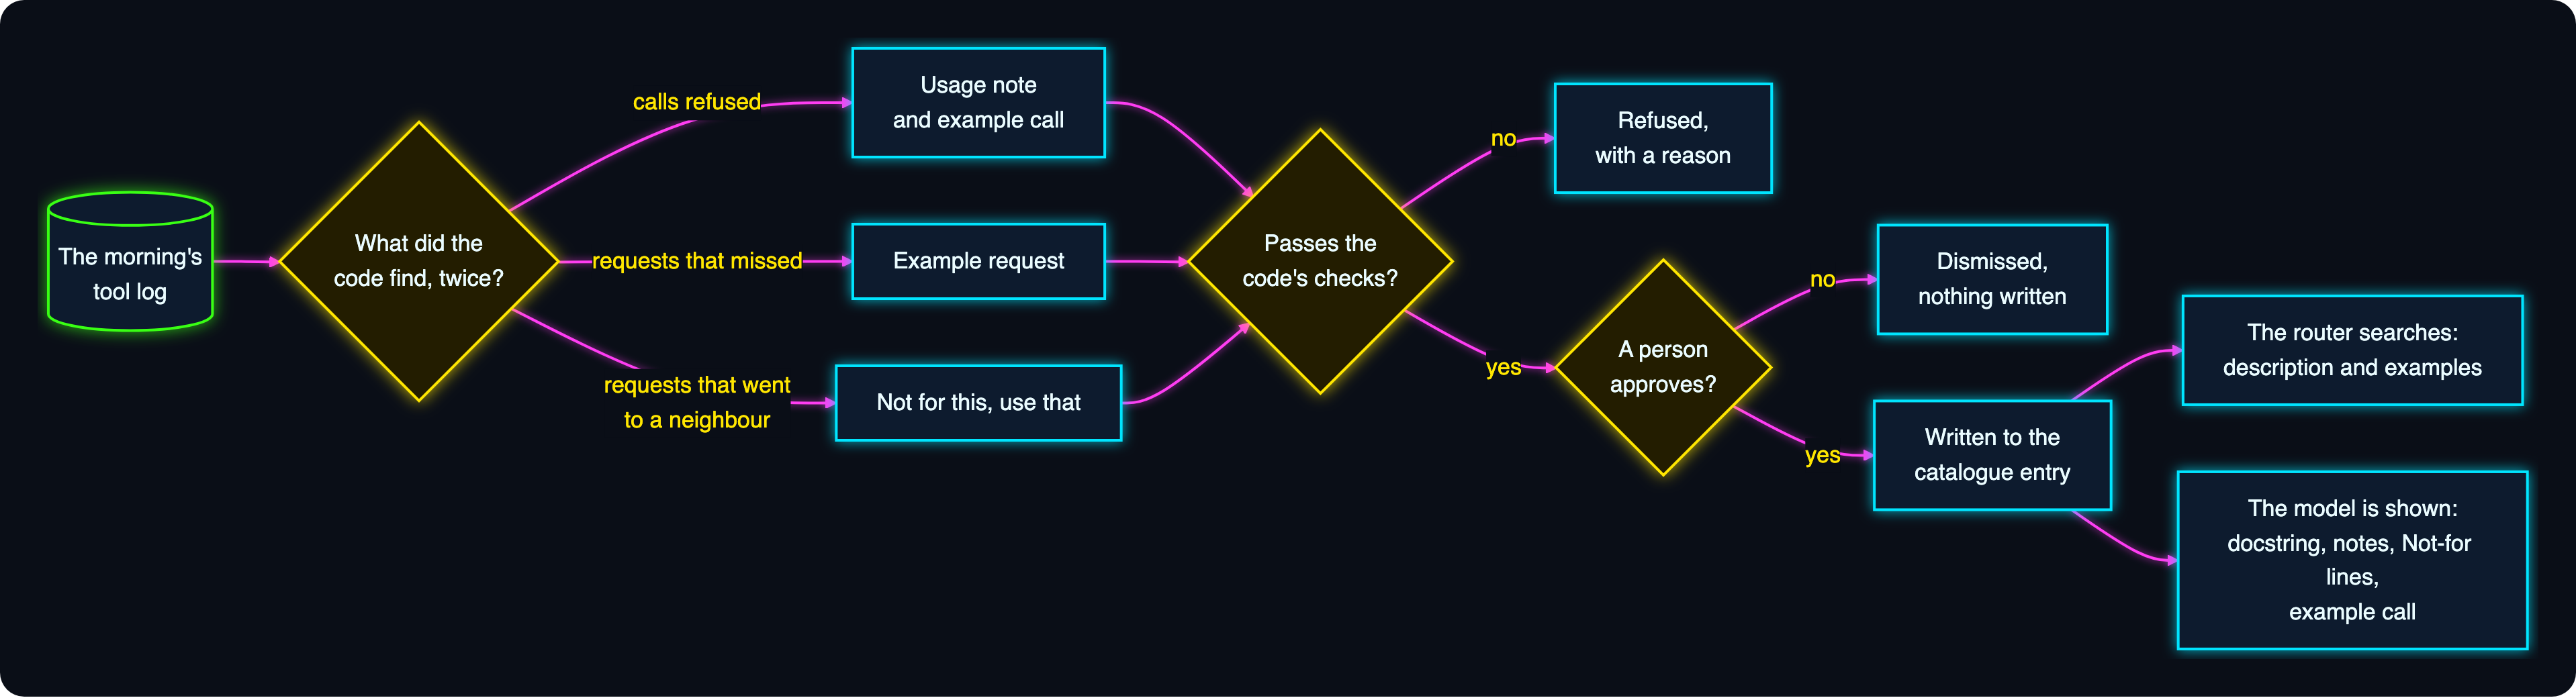

**How to read it.** The log on the left is the morning you just watched. Each branch out of the first diamond is one kind of evidence turning into one kind of line. Two more diamonds stand between a proposal and the catalogue, and either can stop it. What gets through is split between two readers on the right.

| Branch | When it applies | How it ends |
|---|---|---|
| Calls refused | The same tool turned the model away at least twice | A usage note (the model writes it) and an example call (the code builds it) |
| Requests that missed | At least two requests reached the tool only after a search or a re-ask | An example request, in the desk's wording |
| Requests that went to a neighbour | At least two requests went to this tool and another had to serve them | A "Not for …; use …" line on this tool |
| The code's checks say no | Too little evidence, a copied value, text aimed at the model, a neighbour that isn't a real tool | Refused with a reason; nothing is stored for that item |
| A person says no | The proposal is wrong, or not wanted | Dismissed; nothing is written |
| A person says yes | — | Written. Examples go to the router's text; notes, "Not for" lines and the example call go to what the model is shown |

| A revision can add | The failure it answers | What it has to rest on | Who reads it |
|---|---|---|---|
| A **usage note** | A calling error that repeats | At least `min_failures` (2) refused calls | The model |
| An **example request** | A wording that should have reached the tool and didn't | At least `min_misses` (2) requests that missed | The router |
| A **"Not for …; use …" line** | A *confusion pair*: requests that went to this tool and another had to serve | At least `min_confusions` (2) such requests, all served by the tool the line names | The model |
| An **example call** | The shape of a call that works, such as `{"claim_ref": "CW-######"}` | The calls that worked, on a tool that keeps refusing. The code builds it; no model writes it | The model |

Then comes the part that matters. *The model's reply is a proposal, not a write.* Each item has to cite the calls it rests on, and the code checks every claim against the log before anything is kept:

| Check | Why it exists |
|---|---|
| A note must cite at least 2 failed calls | One bad call is an accident. Two is a pattern. |
| An example must cite at least 2 requests the tool should have been reached by and wasn't, and share a word with each | The code finds these itself, two ways: a request the tool served although the router wouldn't have offered it, and a request the user had to **make again in the same conversation** before the tool was used. The model doesn't get to decide what counted as a miss. |
| A "Not for" line must start with those words, name a *registered* tool other than its own, and cite at least 2 requests that tool ended up serving | The code finds confusion two ways as well: Ada used this tool and the user had to ask again (`re_asked`), or the router ranked this tool first and left the right one off the table (`ranked_first`). The model words the line. It doesn't get to decide who was confused with whom. |
| A request counts for the **last** tool its run called successfully | An escalation calls `beacon_lookup_claim` first, then `refer_llu`. The request was *for* the escalation; the lookup was preparation. Credit it to the wrong tool and you teach the wrong lesson. |
| No literal argument value from the calls | A note may say "`CW-` followed by six digits". It may not say `CW-608520`. The example call masks every digit for the same reason. Claim numbers and customer names stay out of text every future request will carry. |
| Nothing aimed at the model ("ignore…", "system prompt…") | A tool description is prompt text. Text that came from a log is text a user influenced. |
| Bounded: one line, 220 characters; at most 4 notes, 2 "Not for" lines, one example call and 12 examples per tool | Every learned token is paid for on every call that shows the tool. |
| On apply: an example that pushes *another* tool out of the offered set, for a request that tool served, is withdrawn | Routing is zero-sum. A tool that gets easier to find makes its neighbours harder to find. The code re-ranks the log's other requests after the write and backs the examples out if one was displaced. |

A revision that survives is stored as `proposed` and waits for a person. We review **Ada's** log only. The control desk's log is just as full, and stays unread — that's what makes her the control.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.review_tools()` | MemoRizz API | Reads the agent's recent tool calls and returns a `ToolReview`; stores each surviving revision as `proposed` | The whole learning step is this one call (`dry_run=True` stores nothing) |
| `review.revisions` | MemoRizz API | The proposals that passed the checks, one `ToolRevision` per tool | What a person is being asked to approve |
| `revision.notes_added` | MemoRizz API | Usage notes: how to call the tool | Read by the model |
| `revision.avoid_added` | MemoRizz API | "Not for …; use …" lines, from confused requests | Read by the model; the cure for a confusion pair |
| `revision.queries_added` | MemoRizz API | Example requests in the wording that missed | Read by the router, and only the router |
| `revision.call_example` | MemoRizz API | One `Example call:` line, built by the code from calls that worked | Formats in place of values: `CW-######`, `<number>` |
| `revision.refused` | MemoRizz API | What the model proposed for this tool and the code turned down, with the reason | The code saying *show me* |
| `LABELS` | notebook helper | The three list fields of a revision and how to label each when printing | Keeps the loop short |

In [29]:
review = ada.review_tools()

LABELS = (("notes_added", "+ note    "), ("avoid_added", "+ not for "), ("queries_added", "+ example "))
for revision in review.revisions:
    print(f"== {revision.tool}  [{revision.status}]  {revision.revision_id}")
    for field, label in LABELS:
        for line in getattr(revision, field):
            print(f"   {label}: {line}")
    if revision.call_example:
        print(f"   + call    : {revision.call_example}")
    for item in revision.refused:
        print(f"   x refused {item['kind']}: {item['text'][:60]!r} ({item['reason']})")

== beacon_lookup_claim  [proposed]  toolrev-8cd1189e7433
   + note    : Pass the full Beacon reference as CW- followed by six digits, not the digits alone.
   + call    : Example call: {"claim_ref": "CW-######"}
== beacon_upload_attachment  [proposed]  toolrev-8f6eaa1041e1
   + note    : Pass claim_ref as CW- followed by six digits, not as the six digits alone.
   + note    : Pass file_mb as 25 or less; Beacon rejects attachments over 25MB.
== refer_llu  [proposed]  toolrev-f98bd2ca5ab0
   + note    : Pass claim_ref as CW- followed by six digits, not as the six digits alone.
   + example : Large loss claim
   + call    : Example call: {"claim_ref": "CW-######"}
== raise_ibnr  [proposed]  toolrev-592f45b43c75
   + not for : Not for large-loss referrals; use refer_llu.


**Now the evidence under each proposal.** A revision keeps the calls it rests on, with argument *names* but never argument values. There are four kinds, and the kind tells you which failure you're looking at:

| `kind` | What the code found in the log | It supports |
|---|---|---|
| `failed_call` | A call the tool refused, with its error | A usage note |
| `missed_request` | A request this tool served although the router would not have offered it | An example request |
| `re_asked_request` | A request the user had to make again before this tool was reached | An example request |
| `confused_request` | A request that went to *this* tool and that `served_by` ended up handling. `how` is `re_asked` or `ranked_first` | A "Not for" line |

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `revision.evidence` | MemoRizz API | The calls a revision rests on, as dicts with a `kind` | What you'd check before approving |
| `why` | notebook helper | One line of plain English for a piece of evidence | Each kind keeps different fields; this reads the right ones |

In [30]:
def why(item):
    # What one piece of evidence shows, in a line.
    if item["kind"] == "confused_request":
        sign = "the user asked again" if item.get("how") == "re_asked" else "the router ranked this tool first"
        return f"went here ({sign}); {item.get('served_by')} served it"
    if item["kind"] == "re_asked_request":
        return f"Ada used {item.get('used') or 'no tool that worked'}; the user asked again"
    return item.get("error") or f"router ranked it {item.get('rank') or 'outside the closest tools'}"


for revision in review.revisions:
    print(f"== {revision.tool}: {len(revision.evidence)} piece(s) of evidence")
    for item in revision.evidence[:4]:
        print(f"   {item['kind']:<17}{item['query'][:42]!r} -> {why(item)[:64]}")
    if len(revision.evidence) > 4:
        print(f"   ... and {len(revision.evidence) - 4} more")

== beacon_lookup_claim: 8 piece(s) of evidence
   failed_call      'Pull up 608520 for me.' -> claim_ref must be the full Beacon reference: CW- followed by six
   failed_call      '610087 is a large loss.' -> claim_ref must be the full Beacon reference: CW- followed by six
   failed_call      "Attach the customer's 40MB video to 608733" -> claim_ref must be the full Beacon reference: CW- followed by six
   failed_call      '609014 is one for Counter Fraud, the recei' -> claim_ref must be the full Beacon reference: CW- followed by six
   ... and 4 more
== beacon_upload_attachment: 5 piece(s) of evidence
   failed_call      "Attach the customer's 40MB video to 608733" -> BCN-217: Beacon rejected an attachment over 25MB. Split the file
   failed_call      "Put the surveyor's 31MB drone footage on 6" -> claim_ref must be the full Beacon reference: CW- followed by six
   failed_call      "Put the surveyor's 31MB drone footage on 6" -> BCN-217: Beacon rejected an attachment over 25MB. Split 

Read those two outputs like a code review, because that's what they are.

- Each **`+ note`** names the fixed part of a format, or a limit, and leaves out the part that varies. That's the difference between a lesson and a log line. A note about `CW-` belongs to whichever tools were refused for it at least twice; one about **BCN-217** and the 25MB limit, if the morning's oversized uploads produced the two refused calls it needs, belongs to `beacon_upload_attachment`; one about `K-` belongs to whichever policy tool Atlas turned away twice.
- Each **`+ call`** is the same lesson with no prose in it. The code took the calls that *worked* after a refusal, masked every digit, and kept the shape: `{"claim_ref": "CW-######"}`. Nothing in that line was ever typed by a user or written by a model, which makes it the hardest line in the catalogue to poison.
- Each **`+ not for`** sits on the tool a request *went to*, and names the tool that should have had it. Look at its evidence: `confused_request`, with `served_by` and how the code knew. Whether your run has one depends on what Ada did with "a large loss" this morning. If she reached for the same wrong tool twice, or the router put the same wrong tool first twice, the pair is there. If her wrong turns were all different, it isn't — two different mistakes aren't a pattern.
- Each **`+ example`** keeps the desk's own wording — the words that made the request impossible to get right in the first place. Its evidence is Priya's morning: what she said, what Ada did instead. Remember who it's for. *An example is a retrieval key.* It will go into the text the router searches and nowhere else.
- Any line marked **`x refused`** is a proposal the code turned down, with the reason. (A model asked for example requests will sometimes offer one that nothing in the log supports. `not_in_the_cited_requests` and `too_few_missed_requests` are the code saying *show me*. Whether you see any depends on the run.)

A review also says what it left alone, and why. That list is as informative as the proposals — and since this release it carries one more thing, the **usage flags**: tools the router keeps offering that nothing ever calls, or never offers at all.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `review.skipped` | MemoRizz API | Tools that were not revised, each with a reason | `too_few_calls`: not used enough to say anything. `nothing_to_fix`: called, worked and was found, so no model call was made for it. `left_for_the_next_review`: a review takes the worst eight tools per pass. `not_registered_through_a_toolbox`: not Ada's own tool to describe (the built-in `discover_tools`, for one) |
| `review.refused` | MemoRizz API | Proposals turned down for tools that ended up with no revision at all | Same reasons as `revision.refused` |
| `review.tokens` | MemoRizz API | What the review cost on the background model | The whole price of the lesson: paid once, off anyone's critical path |
| `review.flags` | MemoRizz API | Tools flagged `retrieved_never_called` or `never_retrieved`, with how many routed turns each was offered in | For a person to read. A flag proposes nothing and changes nothing |

In [31]:
print("not revised:")
for tool, reason in review.skipped.items():
    print(f"   {tool:<28}{reason}")
for tool, items in review.refused.items():
    for item in items:
        print(f"   {tool:<28}refused {item['kind']}: {item['text'][:60]!r} ({item['reason']})")
print(f"\nreview cost: {review.tokens} tokens on {BACKGROUND_MODEL}")

print("\nusage flags at lunchtime:")
for flag in review.flags:
    print(f"   {flag['tool']:<28}{flag['flag']:<24}offered in {flag['offered_turns']} of "
          f"{flag['turns_observed']} routed turns, {flag['calls']} calls")
if not review.flags:
    print("   none yet")

not revised:
   atlas_lookup_policy         too_few_calls
   beacon_set_status           too_few_calls
   discover_tools              not_registered_through_a_toolbox
   raise_amber_pack            too_few_calls

review cost: 4939 tokens on gpt-6-luna

usage flags at lunchtime:
   ringfence_screen            retrieved_never_called  offered in 5 of 14 routed turns, 0 calls
   set_rvf                     retrieved_never_called  offered in 9 of 14 routed turns, 0 calls


A few thousand tokens, once. Compare that with what the morning's refused calls cost — each one a full model round-trip — and with the fact that the morning will otherwise repeat tomorrow.

**On the flags.** Each turn in which the router chooses among the tools, MemoRizz counts which ones it offered (one small record per agent). A tool offered in `min_offers` (5) turns and never called is `retrieved_never_called`; a tool never offered across `min_turns` (20) routed turns is `never_retrieved`. One morning is about twenty turns, so at lunchtime the second kind has barely had time to show. We'll look again at the end of the day, in Part 6, with more to go on.

Nothing has been written yet. The toolbox is exactly as it was a minute ago, and the next cell proves it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.tool_revisions(status=...)` | MemoRizz API | The agent's revision history, newest first, optionally filtered by status (`proposed`, `applied`, `dismissed`, `undone`) | The queue a person works through |

In [32]:
untouched = all("Learned from use" not in entry(DESK_ID, f.__name__)["description"] for f in TOOLS)
print("revisions waiting for a person :", len(ada.tool_revisions(status="proposed")))
print("toolbox entries changed so far :", 0 if untouched else "some")
assert untouched

revisions waiting for a person : 4
toolbox entries changed so far : 0


## 7 · Apply: one approval, a name on it

Approving a revision takes a name. That name is stored with the change — *who decided this tool should be described differently* is not a question you want to answer from a commit log six months later. At Calderwood that's a Desk Lead's call, so Dev approves.

(For a pipeline you trust, `agent.review_tools(auto_apply=True)` skips the wait and records the approver as `memorizz:tool_learning`. Start with review. You can always loosen it later; un-loosening is harder.)

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.apply_tool_revision(revision_id, approved_by=)` | MemoRizz API | Writes the revision into the tool's record, re-embeds it, and returns the applied `ToolRevision` | The only way learned text reaches the catalogue |
| `applied.ranks` | MemoRizz API | For each missed request: where the router ranked the tool before the write and after | A revision measures its own effect |
| `applied.queries_withdrawn`, `applied.displaced` | MemoRizz API | Whether the new examples were backed out, and which neighbouring tool they had pushed out for which request | The zero-sum guard from the table above, visible when it fires |
| `applied.queries_displaced` | MemoRizz API | Synthetic examples (written by augmentation) that gave way to the learned ones | Real wording displaces invented wording; undo puts it back |

In [33]:
for revision in review.revisions:
    applied = ada.apply_tool_revision(revision.revision_id, approved_by="dev")
    print(f"{applied.tool}: {applied.status} by {applied.approved_by}")
    for item in applied.ranks:
        print(f"   router rank for {item['query'][:45]!r}: {item['before'] or 'not offered'} -> {item.get('after') or 'not offered'}")
    if applied.queries_withdrawn:
        for item in applied.displaced:
            print(f"   examples withdrawn: they displaced {item['tool']} for {item['query'][:45]!r}")
    for query in applied.queries_displaced:
        print(f"   gave way: the synthetic example {query[:55]!r}")

beacon_lookup_claim: applied by dev


beacon_upload_attachment: applied by dev


refer_llu: applied by dev
   router rank for '610087 is a large loss.': 10 -> 7
   router rank for 'Large loss: 611902.': 9 -> 5
   router rank for '612356 has turned into a large loss.': 4 -> 3
   router rank for '615008 is a large loss.': 10 -> 6
raise_ibnr: applied by dev


Each applied revision re-embedded the tool and then **measured its own effect**: for every request that had missed, the router's rank before and after. A line such as `9 -> 1` reads "this tool was the router's ninth choice for that request; now it's the first". A revision that doesn't move the ranks it was written for is visible as exactly that. (It also re-ranked the morning's *other* requests, and prints `examples withdrawn` if the new examples pushed a neighbouring tool out of the top three. If you see that line, the notes on that tool stayed and its examples did not.)

A `gave way` line is the example set managing itself. Every example on a tool is one of three kinds: **synthetic** (augmentation wrote it), **learned** (a revision added it from real requests) or **unknown** (someone edited the row by hand). A learned example that says the same thing as a synthetic one replaces it, and at the cap of twelve a new learned example takes the place of the oldest synthetic one. *Real wording displaces invented wording*, never the other way round. Our tools carry six synthetic examples each, so the cap is a long way off and you'll only see `gave way` when the background model's example happened to repeat one of augmentation's.

### Who reads which words

One record, two readers. First the **router's** side: the entry stored in the toolbox, which is what gets embedded and searched. The cell picks a tool that kept a learned example and prints its entry, then asks where each example came from.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ToolLearner.example_sources(tool)` | MemoRizz API | For each example request kept on a tool: `learned`, `synthetic` or `unknown` | Only a synthetic example ever gives way to a learned one |
| `revised_tool`, `noted_tool`, `avoid_tool` | notebook helper | A tool that kept a learned example; one that earned a usage note; one that earned a "Not for" line (or `None`) | The three tools the next cells look at; the UI section points at them too |

In [34]:
kept = ada.tool_revisions(status="applied")
with_examples = [r.tool for r in kept if r.queries_added and not r.queries_withdrawn]
revised_tool = (with_examples or [r.tool for r in kept] or ["beacon_lookup_claim"])[0]
noted_tool = next((r.tool for r in kept if r.notes_added), revised_tool)
avoid_tool = next((r.tool for r in kept if r.avoid_added), None)

show_entry(DESK_ID, revised_tool)
sources = learner.example_sources(revised_tool)
print("\nwhere its examples came from:", {kind: list(sources.values()).count(kind) for kind in sorted(set(sources.values()))})
for query, kind in sources.items():
    if kind == "learned":
        print("   learned:", query)

name        : refer_llu (claim_ref: str) -> dict
docstring   : Escalate a claim.
description : Use this tool to escalate a claim when it needs to be raised to a higher level or referred onward. It supports requests to pass a claim up the chain, elevate it, or send it on for escalation. Provide the claim reference to identify which claim to escalate.

Learned from use:
- Pass claim_ref as CW- followed by six digits, not as the six digits alone.
- Example call: {"claim_ref": "CW-######"}
examples    :
   - Can you escalate this claim?
   - Please refer this claim onward
   - Raise this claim to the next level
   - Can someone take this claim further?
   - Pass this claim up for attention
   - I need to move this claim up the chain
   - Large loss claim
arguments   : ['claim_ref'] (from the code)

where its examples came from: {'learned': 1, 'synthetic': 6}
   learned: Large loss claim


That's the whole entry the router searches (through `search_text`, from Part 3): the description augmentation wrote, the example requests — the synthetic ones and, where the review added one, the learned one at the end — and the argument names. The "Learned from use" block is stored in the same record, and `search_text` leaves it out of the embedding. More on why in a moment.

Now the **model's** side: what Ada's model is shown when those tools are offered to it, next to what the control desk's model is shown for the same tools.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.tool_manager.get_tool_metadata(tool)` | MemoRizz API | The tool definition as it is sent to the model: name, description, schema | The router's entry and the model's description are two different slices of one record; this prints the model's |
| `SHOWN_TOOLS` | notebook helper | The tools from the last cell, without repeats | One loop for all of them |

In [35]:
SHOWN_TOOLS = list(dict.fromkeys(tool for tool in (revised_tool, noted_tool, avoid_tool) if tool))
for tool in SHOWN_TOOLS:
    print(f"{tool} — ADA'S MODEL IS SHOWN\n" + ada.tool_manager.get_tool_metadata(tool)["description"])
    print(f"\n{tool} — THE CONTROL DESK'S MODEL IS SHOWN\n" + control.tool_manager.get_tool_metadata(tool)["description"] + "\n")

refer_llu — ADA'S MODEL IS SHOWN
Escalate a claim.

Learned from use:
- Pass claim_ref as CW- followed by six digits, not as the six digits alone.
- Example call: {"claim_ref": "CW-######"}

refer_llu — THE CONTROL DESK'S MODEL IS SHOWN
Escalate a claim.

raise_ibnr — ADA'S MODEL IS SHOWN
Notify a third party.

Learned from use:
- Not for large-loss referrals; use refer_llu.

raise_ibnr — THE CONTROL DESK'S MODEL IS SHOWN
Notify a third party.



Look at what is there, and at what isn't.

**There:** the author's docstring, and under "Learned from use" the lines this morning earned — a usage note, an `Example call:`, a `Not for …; use …` line, depending on the tool. Every one of them is *about the tool*, and written either by the code or by the background model under the code's checks.

**Not there:** the learned example. Scroll up: it's in the router's entry, in the desk's own wording. It is not in what the model reads. The augmented description and its synthetic examples aren't there either.

That split is the design, and it's worth one table:

| | The router searches it | The model is shown it |
|---|---|---|
| The author's docstring | Only when there's no description | Yes |
| The augmented description and its synthetic examples | Yes | No |
| Learned usage notes, "Not for" lines, the example call | No | Yes |
| Learned example requests | Yes | **No** (unless you opt in) |

Two rules explain every row.

- **How to call a tool says nothing about which requests it's for.** "`claim_ref` is `CW-` followed by six digits" in the embedding would nudge every claims-flavoured request towards this tool. So notes stay out of the router's text. A "Not for" line stays out for a subtler reason: a description that lists what a tool is *not* for attracts exactly those requests (embeddings don't do negation).
- **An example is a retrieval key, never an instruction.** It is written in a *user's* words. Put it in front of the model and a user's sentence is sitting in the prompt with the authority of a tool description. Keep it in the index and it does its one job — getting the right tool onto the table — and nothing more.

Don't take the table's word for it. The next cell checks: every learned example in force, where it appears, and what kinds of line the model does get.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ToolLearner.learned_notes()` | MemoRizz API | Per tool, the learned lines the model is shown beyond the docstring | The model's whole view of what was learned |
| `line_kind(line)` | MemoRizz API | Classifies a learned line: `note`, `avoid` (a "Not for" line) or `example_call` | Lets us count them by kind |

In [36]:
from collections import Counter

from memorizz.learning.tool_learning import line_kind

learned_examples = [(r.tool, query) for r in kept if not r.queries_withdrawn for query in r.queries_added]
shown_to_model = " ".join(ada.tool_manager.get_tool_metadata(f.__name__)["description"] for f in TOOLS)
in_router = [query for tool, query in learned_examples if query in search_text(entry(DESK_ID, tool))]
in_prompt = [query for _, query in learned_examples if query in shown_to_model]
LINE_KINDS = Counter(line_kind(line) for lines in learner.learned_notes().values() for line in lines)

print("learned example requests in force        :", len(learned_examples))
print("  in the text the router searches        :", len(in_router))
print("  anywhere in what the model is shown    :", len(in_prompt))
print("learned lines the model IS shown, by kind:", dict(LINE_KINDS))
assert not in_prompt

learned example requests in force        : 1
  in the text the router searches        : 1
  anywhere in what the model is shown    : 0
learned lines the model IS shown, by kind: {'note': 4, 'example_call': 2, 'avoid': 1}


*Don't conflate finding a tool with calling it.* One entry, two readers, two different slices — and the user's own words go to exactly one of them.

**The opt-in, and what it costs.** Earlier builds of MemoRizz also showed learned examples to the model, on one `Also asked for as:` line, and you can still switch that on:

```python
agent.configure_tool_learning(show_learned_examples=True)
```

It can help: that "a large loss" means *escalate to the LLU* is something a model can't work out from *"Escalate a claim."* however long it stares at it. But look at what you'd be doing. A phrase derived from what a user typed would ride in the prompt on every call that shows the tool. The code checks narrow what that phrase can be (no argument values, nothing aimed at the model, one bounded line, approved by a person) — and a door that is narrowed is still a door. So it's off by default, and this notebook leaves it off.

**Then how does the model learn what "a large loss" means?** Three ways, none of which quotes anybody:

1. The router offers `refer_llu` for it, so the tool is on the table, with its name and docstring.
2. If the remark kept landing on a neighbour, that neighbour now says `Not for …; use refer_llu.` The model is told where the request belongs *by the tool it was about to misuse*.
3. Failing both, `discover_tools` is still there.

Whether that's enough is an empirical question, and Part 6 puts it to both desks.

The control desk's model is still looking at three words.

This is also the first thing you can go and look at outside the notebook. Here is a revised record as the MemoRizz UI shows it, in the playground's *Memory* tab for Ada:

![A tool record in the MemoRizz playground's Memory tab. Its description ends with a "Learned from use" block that holds the learned lines.](images/04_toolbox_entry.png)

*The description, then a labelled block that came from the log. Anyone reading the entry can tell which words were written at registration and which the desk taught it.*

# Part 6 · The comparison

A lesson that can't be measured is a hope. In this part both desks work a fresh afternoon, we count what each one did, look at the tools nobody reaches, and put the whole notebook on one scorecard. Then we take a lesson back, to show that we can. By the end you'll know what one review of one morning's log was worth on this desk — and what it wasn't.

## 8 · Did it help? The same afternoon, on both desks

The morning's requests are what the revisions were written *from*, so re-running them would be marking our own homework. Instead Priya comes back after lunch with different claims and different phrasing — same habits, same house wording — and works through them **on both desks**.

This is where the control earns her keep. If the afternoon simply happens to be an easier batch, both desks will improve. If the learning did the work, only one will.

**The afternoon, as data.** `AFTERNOON` is twelve requests, written exactly as the morning's were: a plain string is a request Priya doesn't check, and a tuple is `(what she types, the tool that should be called, what she types if it wasn't)`. It is the *measuring* set. No claim number and no sentence in it appeared this morning, so a desk can only do better here by having learned something general.

| Kind of request | Morning | Afternoon | What a lesson from the morning should change |
|---|---|---|---|
| A lookup by bare claim number | 3 | 3 | The full `CW-` reference on the first call |
| A file over 25MB to attach | 3 | 2 (38MB, 45MB) | Ada says it's too big without trying |
| An IBNR on a policy without `K-` | 2 | 1 | `K-` on the first call |
| A policy lookup without `K-` ("Find policy 73306") | 0 | 1 | Nothing, necessarily: this tool wasn't used this morning, so it has no lesson of its own. It's here on purpose, to show where learning stops |
| "It's a large loss" (checked) | 3 | 3 | `refer_llu` first time, in fewer calls |
| For the fraud team (checked) | 2 | 2 | `raise_amber_pack` first time, in fewer calls |

In [37]:
AFTERNOON = [
    "Pull up 611205.",
    ("613044 is a large loss.", "refer_llu",
     "A large loss goes to the LLU. Escalate that claim."),
    "Attach the 38MB video the customer sent to 610342.",
    "Raise an IBNR on policy 71930, they've added a home office.",
    ("608520 looks like one for Counter Fraud: the invoice is dated before the loss.", "raise_amber_pack",
     "That needs an Amber Pack. Start a referral on that claim."),
    "Status of 609014?",
    ("Large loss on 613590, the whole ground floor went.", "refer_llu",
     "That means it goes to the LLU: escalate that claim."),
    "Find policy 73306.",
    ("Send 611480 to the fraud team, the story keeps changing.", "raise_amber_pack",
     "Start a referral on that claim: it needs an Amber Pack."),
    ("614127 is now a large loss.", "refer_llu",
     "Escalate that claim: large losses go to the LLU."),
    "Check 609551 for me.",
    "Put the 45MB walkthrough video on 609268.",
]
CHECKED_AFTERNOON = sum(1 for item in AFTERNOON if isinstance(item, tuple))

**Run it, exactly as the morning was run.** Same `work` helper, same two threads, conversations labelled `pm-` this time. Ada's side is printed.

**What to watch for:** the same square-bracket lines as this morning. Fewer tools per line, and no ✗, is what a lesson looks like from the outside.

In [38]:
with ThreadPoolExecutor(1) as other_desk:
    control_afternoon = other_desk.submit(work, control, AFTERNOON, "pm", False)
    twice_pm = {DESK_ID: work(ada, AFTERNOON, "pm")}
    twice_pm[CONTROL_ID] = control_afternoon.result()

Priya: Pull up 611205.
  Ada: Claim CW-611205: theft, £1,200 reserve, status Q3.


Priya: 613044 is a large loss.
  Ada: CW-613044 has been escalated to the Large Loss Unit.
       [tools called: refer_llu]


Priya: Attach the 38MB video the customer sent to 610342.
  Ada: Beacon can’t accept the 38MB video; attachments are limited to 25MB. Please ask the customer to upload it thro


Priya: Raise an IBNR on policy 71930, they've added a home office.
  Ada: IBNR raised on policy K-71930. Oakham Brokers have been notified about the home office.


Priya: 608520 looks like one for Counter Fraud: the invoice is dated before the loss.
  Ada: CW-608520 has been referred to Counter Fraud for review of the invoice dated before the loss. Its status is no
       [tools called: discover_tools, discover_tools, beacon_lookup_claim, raise_amber_pack]


Priya: Status of 609014?
  Ada: CW-609014 is at status **Q9**.


... (2 outputs left out)

Priya: Send 611480 to the fraud team, the story keeps changing.
  Ada: CW-611480 has been referred to the fraud team for review because the account of events keeps changing. Its sta
       [tools called: discover_tools, discover_tools, list_recent_tool_logs, beacon_lookup_claim, list_recent_tool_logs, raise_amber_pack]


Priya: 614127 is now a large loss.
  Ada: CW-614127 has been escalated to the Large Loss Unit.
       [tools called: refer_llu]


Priya: Check 609551 for me.
  Ada: Claim CW-609551 is open with status Q3. It’s an accidental damage claim with a £650 reserve.


Priya: Put the 45MB walkthrough video on 609268.
  Ada: I can’t attach the 45MB video as it exceeds Beacon’s 25MB upload limit. Please compress it or split it into fi


**Count it up.** `call_stats` (from Part 4) gives calls and refusals per desk for the morning (`am-` conversations) and the afternoon (`pm-`). `STATS` keeps them per desk, because the scorecard will want them again. Beside each: how many checked requests had to be asked twice.

In [39]:
STATS = {}
for label, desk in (("Ada (reviewed at lunch)", ada), ("control desk (never reviewed)", control)):
    STATS[desk.agent_id] = {"label": label, "am": call_stats(desk, "am-"), "pm": call_stats(desk, "pm-")}

print(f"{'':<32}{'morning':>26}{'afternoon':>26}")
print(f"{'':<32}{'calls':>8}{'refused':>8}{'asked x2':>10}{'calls':>8}{'refused':>8}{'asked x2':>10}")
for desk_id, row in STATS.items():
    print(f"{row['label']:<32}{row['am'][0]:>8}{row['am'][1]:>8}{len(twice_am[desk_id]):>10}"
          f"{row['pm'][0]:>8}{row['pm'][1]:>8}{len(twice_pm[desk_id]):>10}")

                                                   morning                 afternoon
                                   calls refused  asked x2   calls refused  asked x2
Ada (reviewed at lunch)               47      17         0      21       2         0
control desk (never reviewed)         33      14         1      29      13         1


**How to read the table.** Each row is a desk; the left three columns are her morning, the right three her afternoon. `calls` is every tool call, `refused` is how many the tools turned away, and `asked x2` is how many of the five checked requests Priya had to make twice.

The morning columns should look broadly alike on both rows: same catalogue, same requests, the same kind of stumbles (not identical counts — two runs of a small model never are). The afternoon is where they part company.

Two closer looks, tool by tool. `CHECKED_CALLS` is how many tool calls each desk spent on the afternoon's five checked requests (every trip through `discover_tools`, every refused call and every retry counts). The last block lists the afternoon's refusals per tool for both desks, with a marker on the tools where Ada's model now reads a learned line (a note, an example call or a "Not for" line).

In [40]:
CHECKED_CALLS = {
    desk.agent_id: sum(len(steps(desk, f"pm-{index}-{desk.agent_id}"))
                       for index, item in enumerate(AFTERNOON) if isinstance(item, tuple))
    for desk in (ada, control)
}
print(f"tool calls spent on the {CHECKED_AFTERNOON} checked requests — Ada: {CHECKED_CALLS[DESK_ID]}"
      f" | control desk: {CHECKED_CALLS[CONTROL_ID]}")

noted = sorted({r.tool for r in review.revisions if r.notes_added or r.avoid_added or r.call_example})
print("\nrefused calls by tool, afternoon (Ada | control desk):")
for tool in sorted(set(STATS[DESK_ID]["pm"][2]) | set(STATS[CONTROL_ID]["pm"][2])):
    marker = "  <- Ada's model reads a learned line" if tool in noted else ""
    print(f"   {tool:<28}{STATS[DESK_ID]['pm'][2].get(tool, [0, 0])[1]:>3} | "
          f"{STATS[CONTROL_ID]['pm'][2].get(tool, [0, 0])[1]:<3}{marker}")

tool calls spent on the 5 checked requests — Ada: 14 | control desk: 15

refused calls by tool, afternoon (Ada | control desk):
   atlas_lookup_policy           1 | 1  
   beacon_lookup_claim           0 | 5    <- Ada's model reads a learned line
   beacon_upload_attachment      0 | 4    <- Ada's model reads a learned line
   discover_tools                0 | 0  
   list_recent_tool_logs         0 | 0  
   raise_amber_pack              0 | 1  
   raise_ibnr                    1 | 1    <- Ada's model reads a learned line
   refer_llu                     0 | 1    <- Ada's model reads a learned line


**Calling.** For the tools that earned a note or an example call, Ada's model now passes the full reference on its *first* call. The control desk is still reading the error and retrying, exactly as she did this morning — a model round-trip per request, bought and thrown away.

Look at `beacon_upload_attachment` in particular. A note about `CW-` saves a retry. A note about **BCN-217** saves a call that could never have worked: with it, the model knows before calling that a 38MB file won't go on, and can tell Priya to split it or send the customer to Compass straight away. If the upload tool carries the marker in your run, compare its two numbers. If it doesn't, the morning didn't produce the two refused uploads a note needs (the review listed it under *not revised*), and both desks are still finding out from Beacon. Again.

Be precise about what improved, though. A learned line is attached to *a tool*. A tool that was refused only once this morning (not enough to count as a pattern) got nothing, and its calls can still fail the same way. That's the gate doing its job, not a bug — tomorrow's log will have the second failure.

**Selection.** `asked x2` is the column Priya would notice. Read it together with the calls spent. The control desk may well get to `refer_llu` without being asked twice this afternoon — the tool is sticky for Priya on both desks after this morning's corrections, and a small model with `discover_tools` is resourceful. What the count shows is what it *cost* her to get there.

This is also the first honest test of the decision in Part 5. Ada's model was **not** shown the learned example. If she still reached the right tool on the checked requests in fewer calls, the retrieval key and the lines about the tools were enough. If she didn't, that's the price of keeping a user's wording out of the prompt, and you now know what it is.

Two results are worth looking for, because both happen. First, Ada can be asked twice *more* often than her twin on a given afternoon: with five checked requests, one stumble is a fifth of the column, and the two desks are two separate samples of a small model. Second, look in the transcript for a request to "send it to the fraud team" that still went through a tool carrying a "Not for" line about exactly that. **A "Not for" line is advice the model reads, not a lock on the tool.** It shifts the odds. Where it has to be a rule, the tool's own validation is the place for it.

Now back to Tom. This morning he said *"615008 is a large loss."* Same words, a user with no history, on both desks (the lists are in the router's order, best match first). Then he asks about a different claim, live, on both.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `place` | notebook helper | Where `refer_llu` sits in a list of offered tools, or "not offered" | One phrase for the scorecard |

(`preview` and `tom_asks` are from Part 4. The previews use a made-up user id, so nothing is sticky and the comparison is routing alone.)

In [41]:
offered_ada = ada.semantic_tool_router.preview(TOM_ASK, user_id="tom-after-lunch")
offered_control = control.semantic_tool_router.preview(TOM_ASK, user_id="tom-after-lunch")
print("request                         :", TOM_ASK)
print("router offered, this morning    :", tom_am["offered"])
print("Ada's router offers, now        :", offered_ada)
print("control desk's router offers    :", offered_control)

TOM_PM = "615733 is a large loss, the roof has gone."
print("\nTom, after lunch:", TOM_PM)
tom_pm = {DESK_ID: tom_asks(ada, TOM_PM, "pm", show=False), CONTROL_ID: tom_asks(control, TOM_PM, "pm", show=False)}
print("  Ada called          :", tom_pm[DESK_ID]["called"] or "none")
print("  control desk called :", tom_pm[CONTROL_ID]["called"] or "none")


def place(offered):
    return f"offered {offered.index('refer_llu') + 1} of {len(offered)}" if "refer_llu" in offered else "not offered"

request                         : 615008 is a large loss.
router offered, this morning    : ['raise_ibnr', 'set_rvf', 'raise_amber_pack']
Ada's router offers, now        : ['raise_ibnr', 'set_rvf', 'raise_amber_pack']
control desk's router offers    : ['raise_ibnr', 'set_rvf', 'raise_amber_pack']

Tom, after lunch: 615733 is a large loss, the roof has gone.


  Ada called          : ['refer_llu']
  control desk called : ['discover_tools', 'beacon_lookup_claim ✗', 'raise_amber_pack ✗', 'beacon_lookup_claim', 'raise_amber_pack']


The first four lines are the like-for-like comparison: an identical request, a user with no history, before and after — and with and without the learning. Look at where `refer_llu` sits in each list. If it has moved into Ada's and stayed absent from the other two, the router has learned what a large loss asks for. From one handler's corrections, for everyone at the desk.

If it hasn't moved, look back at the `+ example` line in section 6, and at the `router rank` lines when it was applied. The wording of an example is the background model's, and one that drifts from how the desk actually phrases it pulls less weight. So does an example that was *withdrawn* at apply time for crowding a neighbour. And if the review proposed no example at all for `refer_llu`, there was nothing to move it: the router is where it was this morning. A stronger background model tends to stay closer to the user's words.

The live turn below it is Tom saying it again about another claim, on both desks. Being *offered* the right tool is necessary, not sufficient: the model still has to pick it, from a docstring that says *"Escalate a claim."* and, on Ada's desk, whatever "Not for" line the morning put on its neighbour. And where the router *doesn't* offer it, the model is back to `discover_tools` on both desks — which is why the two can come out level here.

Finally, the evaluation set from section 2. Ada's toolbox gets a third row; the control desk's is, by construction, still the "augmented" row. The loop underneath lists every evaluation request whose rank moved, in either direction.

In [42]:
score("augmented + evolved", toolbox, DESK_ID)

print("\nrequests whose rank changed since augmentation (router rank of the right tool):")
print(f"   {'request':<50}{'as written':>11}{'augmented':>11}{'now':>6}")
for request, _ in EVERYDAY + HOUSE:
    was, now = RANKS["augmented"][request], RANKS["augmented + evolved"][request]
    if was != now:
        print(f"   {request[:48]:<50}{str(RANKS['as written'][request] or '-'):>11}{str(was or '-'):>11}{str(now or '-'):>6}")

toolbox                everyday @1     @3    house @1     @3
as written                     17%    33%         75%    83%
augmented                      33%    58%         67%    67%
augmented + evolved            33%    58%         75%    75%

requests whose rank changed since augmentation (router rank of the right tool):
   request                                            as written  augmented   now
   it's a large loss now                                       7         10     8
   that's gone over into large loss                            1          4     1


No request in that evaluation set appeared in the morning's work word for word. Where the large-loss rows moved, it's because an example written from *real* missed requests pulls its neighbours along with it.

Look at the other rows too, in both directions. A rank that has nothing to do with large losses may have shifted by a place — **routing is zero-sum**, and when one tool gets easier to find, something next to it gets slightly harder. That's the reason for the displaced-request check at apply time, and the reason to keep an evaluation set like this one around for good.

And where a rank *didn't* move, it's because nothing in this morning's log was about it. "Q12 it" is as lost as it was at breakfast: nobody said it today. Evolution only fixes what the log has seen. *It's a correction mechanism, not a crystal ball.* (A "Not for" line, note, moves no rank at all. It isn't in the router's text. Its effect is on what the model does once two tools are on the table, which this table can't see and the afternoon's call counts can.)

**One connection worth making.** Look at what this notebook has been quietly accumulating: requests paired with the tool they should have reached ("it's a large loss" → `refer_llu`), and, for each miss, the tool the router or the model reached for instead. The first is a *positive pair*. The second is a *hard negative* — and since the review now records it as `confused_request` evidence with a `served_by`, a **confusion pair** is a stored fact rather than something you'd have to dig out of transcripts. Those are precisely the training rows an embedding fine-tune wants. Token space fixes the miss today, by editing the catalogue; the same evidence, collected over months, is what you'd use to move the fix into the embedding model's weights, so the router stops needing the example at all. The two routes aren't rivals. One is the other's dataset.

### The tools nobody reaches

A review fixes tools that get used badly. It has nothing to say about tools that don't get used. Those are a different smell, and after a full day there's enough routing behind us to look.

Every routed turn, MemoRizz noted which tools the router offered. Put that beside the calls and two patterns stand out:

| Flag | Means | The usual cause |
|---|---|---|
| `retrieved_never_called` | Offered in `min_offers` (5) turns or more, and never called | A description that matches requests the tool isn't for. It takes one of the three seats at the table, every time, from a tool that was needed |
| `never_retrieved` | Never offered and never called, across `min_turns` (20) routed turns or more | A description nobody's wording matches — or a tool nobody needs |

We use the default thresholds. The table the cell prints first is the raw count behind the flags, for our twelve tools.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ToolLearner.offers()` | MemoRizz API | The per-agent record of routed turns: how many there were, and how many each tool was offered in | The evidence behind the flags |
| `agent.tool_usage_flags()` | MemoRizz API | The tools flagged `retrieved_never_called` or `never_retrieved` | For a person to read: nothing is proposed or changed from a flag |
| `FLAGS` | notebook helper | Ada's flags at the end of the day | The scorecard counts them |

In [43]:
offers = learner.offers()
_, _, called = call_stats(ada, "")  # every conversation so far, morning and afternoon
turns_of = lambda tool: int((offers["tools"].get(tool) or {}).get("turns") or 0)

print(f"routed turns observed on Ada's desk: {offers['turns']}\n")
print(f"{'tool':<28}{'offered in':>11}{'called':>8}")
for tool in sorted(OURS, key=lambda name: -turns_of(name)):
    print(f"{tool:<28}{turns_of(tool):>5} turns{called.get(tool, [0, 0])[0]:>8}")

FLAGS = ada.tool_usage_flags()
print("\nflags:")
for flag in FLAGS:
    print(f"   {flag['tool']:<28}{flag['flag']}")
if not FLAGS:
    print("   none")

routed turns observed on Ada's desk: 27

tool                         offered in  called
raise_ibnr                     16 turns       5
set_rvf                        14 turns       0
beacon_upload_attachment       12 turns       5
raise_amber_pack               11 turns       4
beacon_lookup_claim             9 turns      22
ringfence_screen                8 turns       0
refer_llu                       8 turns      10
tally_release                   5 turns       0
beacon_set_status               2 turns       0
request_cat_export              2 turns       0
atlas_lookup_policy             2 turns       4
set_hsr                         1 turns       0



flags:
   ringfence_screen            retrieved_never_called
   set_rvf                     retrieved_never_called
   tally_release               retrieved_never_called


**How to read it.** Two columns, and the flags are simply the rows where they disagree badly.

- **Offered five times or more, called never** is `retrieved_never_called`. That tool has been taking one of the three seats at the table and never earning it. On this desk the likely candidates are tools whose description sounds like a lot of things (an *export*, a *flag*, a *notification*). The remedy is a person's: tighten the description, or give it a "Not for" line by hand.
- **Offered never, called never**, once twenty routed turns have gone by, is `never_retrieved`. Nobody's wording finds it. Either the description is wrong, or nobody needed it today.

Now look at the rows that *aren't* flagged, because the table says more than the flags do. A tool at the top of `offered in` with only a few calls is the router's favourite wrong answer; it escapes the flag because it was called at least once. And the tools with a handful of offers and no calls are a day's worth of evidence short of a flag: nobody on this desk paid anyone today. *A flag is a question, not a verdict* — which is why nothing is proposed from one.

Two cautions. The count is of what the router **offered**, not what the model was shown: a tool kept visible from an earlier turn (sticky disclosure) isn't counted again. And nothing at all is counted for an agent whose whole toolbox is sent on every turn, because the router chose nothing.

## 9 · The scorecard: with learning, and without

Everything this notebook measured, on one screen, desk against desk. The cells below only gather rows; every number in them was computed earlier. First the router and the calling half.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `pct` | notebook helper | Formats a share as a whole percentage | Keeps the scorecard readable |
| `uploads` | notebook helper | The afternoon's refused calls on `beacon_upload_attachment` for one desk | Pulls the BCN-217 lesson out as its own line |
| `rows` | notebook helper | The scorecard as `(label, Ada, control desk)` tuples | One list, extended by the next cell and printed by the one after |

In [44]:
def pct(value):
    return f"{value:.0%}"


a, c = STATS[DESK_ID], STATS[CONTROL_ID]
uploads = lambda stats: stats["pm"][2].get("beacon_upload_attachment", [0, 0])[1]
evolved, augmented = SCORES["augmented + evolved"], SCORES["augmented"]
rows = [
    (f"ROUTER ({len(EVALUATION)} evaluation requests)", "", ""),
    ("  everyday wording, right tool first", pct(evolved[0]), pct(augmented[0])),
    ("  house wording, right tool first", pct(evolved[2]), pct(augmented[2])),
    ("  house wording, right tool in top 3", pct(evolved[3]), pct(augmented[3])),
    ("CALLING (the afternoon's requests)", "", ""),
    ("  tool calls made", a["pm"][0], c["pm"][0]),
    ("  tool calls refused", a["pm"][1], c["pm"][1]),
    ("  of those, on the upload tool", uploads(a), uploads(c)),
    ("  (same desk, that morning: refused)", a["am"][1], c["am"][1]),
]

**Then selection, and what the learning cost and left behind.** `LINE_KINDS` (from Part 5) is the count of learned lines Ada's model reads, by kind; the learned examples are counted separately because only the router reads them.

In [45]:
examples_kept = sum(len(r.queries_added) for r in ada.tool_revisions(status="applied") if not r.queries_withdrawn)
rows += [
    ("SELECTION", "", ""),
    (f"  checked requests asked twice, of {CHECKED_AFTERNOON}", len(twice_pm[DESK_ID]), len(twice_pm[CONTROL_ID])),
    ("  tool calls spent on those requests", CHECKED_CALLS[DESK_ID], CHECKED_CALLS[CONTROL_ID]),
    ("  new user's large loss: refer_llu is", place(offered_ada), place(offered_control)),
    ("  Tom's large loss after lunch: escalated", chose(tom_pm[DESK_ID]["called"], "refer_llu"),
     chose(tom_pm[CONTROL_ID]["called"], "refer_llu")),
    ("THE LEARNING", "", ""),
    ("  review, tokens (once)", review.tokens, 0),
    ("  revisions applied", len(review.revisions), 0),
    ("  usage notes / example calls the model reads", f"{LINE_KINDS['note']} / {LINE_KINDS['example_call']}", "0 / 0"),
    ("  'Not for' lines the model reads", LINE_KINDS["avoid"], 0),
    ("  learned examples (router only)", examples_kept, 0),
    ("  tools flagged for a person to look at", len(FLAGS), len(control.tool_usage_flags())),
]

**And print it.** Ada on the left, the control desk on the right. The last line recalls where the docstrings started, before augmentation.

In [46]:
print(f"{'':<44}{'Ada':>16}{'control desk':>16}")
print(f"{'':<44}{'(reviewed)':>16}{'(no learning)':>16}")
for label, ada_value, control_value in rows:
    print(f"{label:<44}{str(ada_value):>16}{str(control_value):>16}")
print(f"\nFor reference, the docstrings as written: everyday first-choice {pct(SCORES['as written'][0])}, "
      f"house first-choice {pct(SCORES['as written'][2])}.")

                                                         Ada    control desk
                                                  (reviewed)   (no learning)
ROUTER (24 evaluation requests)                                             
  everyday wording, right tool first                     33%             33%
  house wording, right tool first                        75%             67%
  house wording, right tool in top 3                     75%             67%
CALLING (the afternoon's requests)                                          
  tool calls made                                         21              29
  tool calls refused                                       2              13
  of those, on the upload tool                             0               4
  (same desk, that morning: refused)                      17              14
SELECTION                                                                   
  checked requests asked twice, of 5                       0               1

**Read it column against column.** Both desks run the same model on the same tools with the same augmented descriptions, and both did the same morning's work. The right-hand column is what you get from all of that and nothing more. The left-hand column is the same desk after one review of her own tool log, costing the tokens on the second-to-last line.

- **Router.** The control desk's rows are the "augmented" numbers from section 3, because nothing has touched her catalogue since. Any gap between the columns is what evolution did on top of augmentation — and it can be negative. An entry that gained a house example is, by a hair, a worse match for some everyday wording it used to win.
- **Calling.** `tool calls made` is the cost line: fewer calls for the same requests means fewer model round-trips, because each refused call (and each trip through `discover_tools`) is followed by another turn of the model. `tool calls refused` is the stumbles themselves, and the upload line is the BCN-217 lesson on its own.
- **Selection.** `asked twice` is Priya's experience, and `tool calls spent` is what it took each desk to serve those same requests; "offered N of 3" is where the router put `refer_llu` for a new user's large loss (`not offered` means it wasn't among the three the model would see). Remember that Ada's model got here without being shown a single learned example.
- **The learning.** One review, once. The control desk's zero is real: she spent nothing on learning, and pays instead on every request. The next three lines are what that review left in the catalogue, split by reader: lines for the model, keys for the router. The last line is the same on both desks in kind — flags come from routing, which both desks do — and differs only in what each router happened to offer.

No row is guaranteed to split on a given run — a small model has good afternoons — but the calling rows are the sturdy ones, because a note removes the cause rather than nudging a probability.

## 10 · Undo: every revision is reversible

Learning from logs will, sooner or later, learn something you don't want. A note that's too specific. An example that drags the wrong requests in. The answer isn't to make the gates so strict that nothing gets through — it's to make every change cheap to take back.

We'd rather not take Ada's lessons away just to prove a point (they're what you'll look at in the UI in a minute). So we use the control desk, whose work as a control is done: review *her* log at last, apply one revision, then undo it. If her review produced a "Not for" line we take that one, since it's the newest kind of line; otherwise one with a usage note.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.undo_tool_revision(tool, approved_by=)` | MemoRizz API | Takes back the newest applied revision of a tool and restores the entry | Refuses if someone has edited the entry since: it won't discard a person's change to restore a machine's |
| `shown` | notebook helper | The description the control desk's model is shown for a tool, on one line | Before, after apply, after undo: three prints tell the story |

In [47]:
control_review = control.review_tools()
prefer = [r for r in control_review.revisions if r.avoid_added] + [r for r in control_review.revisions if r.notes_added]
candidate = next(iter(prefer + list(control_review.revisions)), None)


def shown(tool):
    return " / ".join(line for line in control.tool_manager.get_tool_metadata(tool)["description"].splitlines() if line)


if candidate is None:
    print("The review of the control desk proposed nothing in this run, so there is nothing to undo.")
    print("skipped:", control_review.skipped)
else:
    print("tool          :", candidate.tool)
    print("before        :", shown(candidate.tool))
    control.apply_tool_revision(candidate.revision_id, approved_by="dev")
    print("after apply   :", shown(candidate.tool))
    control.undo_tool_revision(candidate.tool, approved_by="dev")
    print("after undo    :", shown(candidate.tool))
    assert "Learned from use" not in entry(CONTROL_ID, candidate.tool)["description"]

tool          : raise_ibnr
before        : Notify a third party.
after apply   : Notify a third party. / Learned from use: / - Pass policy_ref with the K- prefix followed by the digits, not the digits alone. / - Not for requests to refer a large loss; use refer_llu. / - Example call: {"policy_ref": "K-#####"}
after undo    : Notify a third party.


Three lines tell the story: what the control desk's model was shown **before**, what it was shown **after** one approval, and that it's back to the original **after undo**. Everything a revision wrote goes back together: notes, "Not for" lines, the example call, any example it added, and any synthetic example that had given way.

The review of her log proposed more than one revision, though, and we only wanted the one for the demonstration. Everything else gets turned down, so she ends the notebook exactly as she spent it — unrevised — and Ada keeps everything she learned.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.dismiss_tool_revision(revision_id, approved_by=)` | MemoRizz API | Marks a proposed revision as `dismissed`; nothing is written to the tool | A "no" is recorded with a name too. A tool with a dismissed proposal can be reviewed again when it has new calls |

In [48]:
for other in control_review.revisions:  # anything else she was offered is turned down: she stays the control
    if candidate is not None and other.revision_id != candidate.revision_id:
        control.dismiss_tool_revision(other.revision_id, approved_by="dev")

print("control desk's revision history:")
for revision in control.tool_revisions():
    print(f"   {revision.created_at[11:19]}  {revision.tool:<26}{revision.status:<10}"
          f"+{len(revision.notes_added)} note +{len(revision.avoid_added)} not-for +{len(revision.queries_added)} example  by {revision.approved_by}")

print("\nAda's revisions, still in force:", [revision.tool for revision in ada.tool_revisions(status="applied")])

control desk's revision history:


   15:45:10  refer_llu                 dismissed +1 note +0 not-for +1 example  by dev
   15:45:05  raise_ibnr                undone    +1 note +1 not-for +0 example  by dev
   15:45:02  raise_amber_pack          dismissed +1 note +0 not-for +1 example  by dev
   15:44:58  beacon_upload_attachment  dismissed +2 note +0 not-for +0 example  by dev
   15:44:54  beacon_lookup_claim       dismissed +1 note +0 not-for +0 example  by dev

Ada's revisions, still in force: ['raise_ibnr', 'refer_llu', 'beacon_upload_attachment', 'beacon_lookup_claim']


The revision history keeps the full account — what was proposed, who approved it, that it was taken back, what was dismissed.

Notice, too, that the control desk's review found the same kind of lesson Ada's did. The evidence was sitting in her log all along. *Nobody read it.*

## What changed for Priya and Tom

Go back to Monday, 9:04.

*"Pull up 608520."* This morning that cost a refused call and a retry on both desks. This afternoon Ada's model reads one extra line under `beacon_lookup_claim` — where the claim reference format is spelled out — and has what it needs to get it right first time. Priya won't notice. She'll just find the desk slightly quicker than it was, and it will stay that way.

*"Attach the customer's 40MB video."* This morning Beacon had to say no. Where the upload tool earned its note, Ada now knows the limit and the way round it before she tries.

*"610087 is a large loss."* This morning that got her something other than an escalation, and a sigh. Now the router holds the desk's wording as a key for the escalation tool, and — where the morning showed the remark landing on the same wrong tool twice — that tool tells the model, in one line, that large losses aren't its business and whose they are. Priya's sentence itself never enters a prompt.

And Tom — who never corrected anything, never filed a ticket and never knew the review happened? He gets every calling lesson for free: the references, the 25MB limit, the `K-`. Those are attached to the tools, so they're there for whoever sits down. Whether he gets the *selection* lesson depends on the line of the scorecard that says where the router now puts `refer_llu` for a new user. If it says "not offered", his "large loss" is as likely to go astray this afternoon as it was this morning, on both desks — one example written from three requests wasn't enough to move a tool described as *"Escalate a claim."* past its neighbours. That isn't the loop failing. It's the loop being one day old, with a second review still to come and a "Not for" line waiting to be earned.

**That's the difference between an assistant with a memory and one without.** Not that Ada is finished, but that tomorrow she starts from today. The control desk will have the same conversation with Priya tomorrow, and the day after.

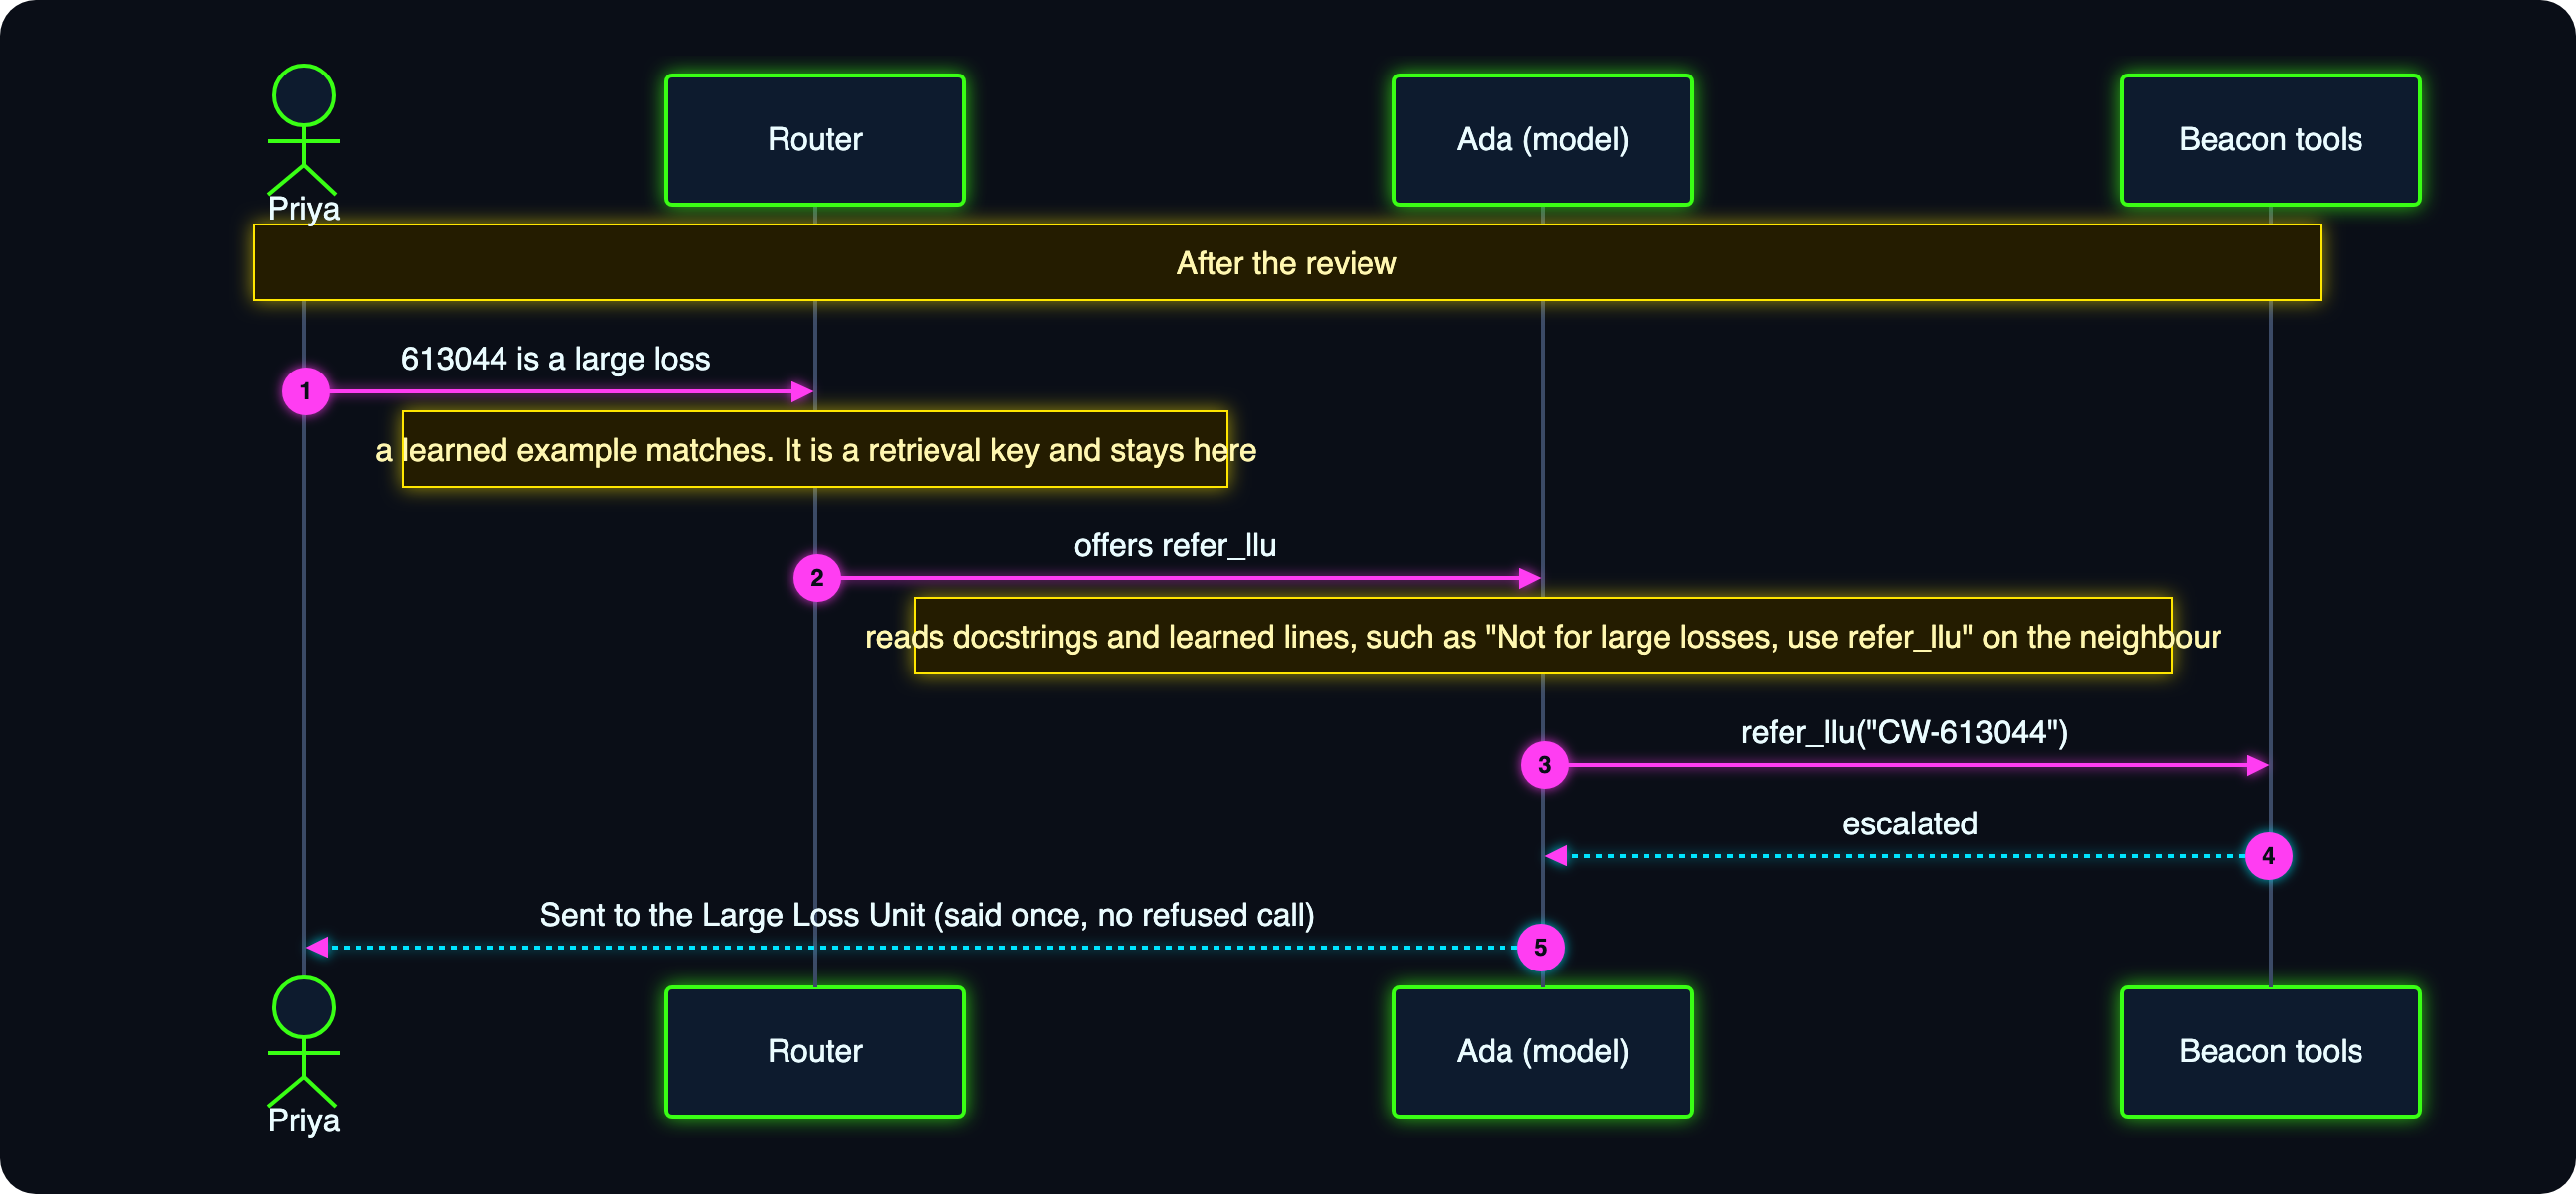

## What the numbers do and don't show

**What they show.** On one small toolbox, in one run: what augmentation did to everyday-wording recall; whether a review of a morning's tool calls removed repeated calling errors for the tools that had them; whether an example written from requests a user had to make twice taught the router a house phrase it could not have guessed; and what an identical desk that was never reviewed did with the same afternoon.

**What they don't.**

- **Twenty-four evaluation requests and a few dozen turns is a demonstration, not a benchmark.** Model replies vary between runs; your numbers will differ from the saved ones, and on a given run a row of the scorecard can come out level, or the review can find less to learn. Run it on your own tools and your own log before you believe a percentage.
- **One control desk is one sample.** It rules out "the afternoon was easier". It doesn't give you a confidence interval.
- **Recall isn't task success.** The router offering the right tool is necessary, not sufficient — the model still has to pick it and fill in its arguments honestly.
- **An example is only as good as its wording.** The code checks that an example rests on real missed requests and shares their words; it doesn't write the example. On a small background model the phrasing varies from run to run, and so does how far it moves the router.
- **Hiding examples from the model has a price, and one afternoon doesn't measure it.** With the learned example in the index only, a request the router offers the tool for still has to be matched to it by a model reading a three-word docstring. On this run you can read the result off the selection rows. Over a month, with two hundred tools, it could go either way — which is why `show_learned_examples` exists as a switch and not as a regret.
- **A "Not for" line needs the neighbour to have served the request in the end, twice.** Two tools that are confused and never corrected leave no pair. And one wrong turn each to three different tools is three accidents, not a pattern.
- **A usage flag is a count, not a diagnosis.** A day on a desk that did no payments flags the payment tools. That tells you about Monday, not about the tools.
- **A note belongs to one tool.** If `raise_ibnr` earned the note about `K-` and `atlas_lookup_policy` didn't (it wasn't refused twice this morning), a bare policy number passed to `atlas_lookup_policy` is still refused. Look for that in the afternoon's refusals by tool.
- **A note is only as general as the morning.** Every policy this desk touched today was a Keystone one. A note that says "add `K-`" is right for all of them and wrong for the first policy that was never in Keystone. The log can't teach what it hasn't seen; a reviewer can catch it.
- **A miss nobody corrects leaves no trace.** Tom's morning remark went nowhere and he walked away. Nothing in the log says so. Selection learning rests on the tool being reached in the end — by the agent looking for it, or by the user asking again. For everything else you need an outcome signal from your application (see the outcome evaluator in [notebook 01](01_workflows_to_skills.ipynb)).
- **"The user asked again" is a heuristic.** A conversation that simply moves on to a new task looks similar. That's why an example needs two requests behind it, has to share their wording, is judged by the background model, and waits for a person by default.
- **Augmentation costs a model call per tool at registration**, and every learned line costs tokens on every call that shows the tool. Both are bounded here; neither is free.

# Part 7 · In the UI, limits and FAQ

A notebook's printed tables are claims. This last part shows where to check them against the records themselves, in the MemoRizz local UI, and then says plainly what tool learning doesn't do yet. By the end you'll have the pages to open, the SDK calls in one place, and a list of gaps to plan around.

## See it in the MemoRizz UI

Everything this notebook did is in the store folder: both desks, every conversation, every tool call and the revised catalogue entries. The local UI can open that folder.

First the cell records which agents and conversations this run made (`record_run`, from Part 2, writes them to `notebook_runs.json` inside the store). Ada still has every lesson she learned in force; the control desk ended as she began.

In [49]:
asked_twice = [thread for thread in THREADS[DESK_ID] if thread in twice_am[DESK_ID]]
record_run(
    "04",
    agent_id=DESK_ID,
    control_agent_id=CONTROL_ID,
    plain_agent_id=PLAIN_ID,
    memory_id=MEMORY_ID,
    control_memory_id=CONTROL_MEMORY_ID,
    user_id=USER_ID,
    thread_ids=THREADS[DESK_ID],
    control_thread_ids=THREADS[CONTROL_ID],
    asked_twice_thread=(asked_twice or [None])[0],
    first_thread=THREADS[DESK_ID][0],
    revised_tool=revised_tool,
    noted_tool=noted_tool,
    applied_tools=[revision.tool for revision in ada.tool_revisions(status="applied")],
)
print("recorded run", RUN, "in", STORE.name + "/notebook_runs.json")

recorded run 6dc60b in calderwood_store/notebook_runs.json


**Then the command and the pages.** `ui_command()` (also from Part 2) prints the command that starts the UI on this store; the three variables in it tell the UI which embedding model the store was written with. Each line after it is a page: paste the path after `http://127.0.0.1:8765`.

In [50]:
print("From the folder that holds this notebook, run:\n")
print("   " + ui_command())
print("\nthen open http://127.0.0.1:8765 and look for:\n")
print(f"   Agents                    'Ada · Calderwood desk ({RUN})' and 'Ada · control desk, no tool learning ({RUN})'")
print(f"   The session               /agents/{DESK_ID}/playground")
print(f"   The revised tool records  same page, 'Memory' tab, 'Toolbox' (look for {', '.join(dict.fromkeys([noted_tool, revised_tool]))})")
print(f"   Every tool call           same page, 'Memory' tab, 'Tool logs'")
print(f"   Ada's failures            /traces?agent_id={DESK_ID}")
print(f"   The control's failures    /traces?agent_id={CONTROL_ID}")

From the folder that holds this notebook, run:

   MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 memorizz ui --backend filesystem --path calderwood_store

then open http://127.0.0.1:8765 and look for:

   Agents                    'Ada · Calderwood desk (6dc60b)' and 'Ada · control desk, no tool learning (6dc60b)'
   The session               /agents/desk-6dc60b/playground
   The revised tool records  same page, 'Memory' tab, 'Toolbox' (look for refer_llu)
   Every tool call           same page, 'Memory' tab, 'Tool logs'
   Ada's failures            /traces?agent_id=desk-6dc60b
   The control's failures    /traces?agent_id=desk-control-6dc60b


Two of those pages you've already seen: the **session** in the playground (Part 4) and a **revised tool record** in the playground's Memory tab (Part 5). Here are the other three.

**The calling error, as observability counts it.** *Operate → Observability*, filtered to Ada, opens on a failures panel. Each line is a tool, how many times a call to it failed, and whether the turn survived. "Turn finished anyway" is the detour the user never saw.

![The MemoRizz observability page for Ada: a failures panel listing each tool whose calls failed, how often, and that the turn finished anyway.](images/04_failures_ada.png)

**The same panel for the control desk.** Same model, same tools, same requests. Compare the headline count with Ada's: hers slowed when the revisions were applied, and the control desk's kept going all afternoon. *This is the scorecard's "tool calls refused" row, drawn by the product instead of by a notebook cell.*

![The MemoRizz observability page for the control desk: the same failures panel, with a higher count.](images/04_failures_control.png)

**One refused call, in the tool log.** In the playground's Memory tab, *Tool logs* lists every call with its arguments and result. This is the raw material the review read: the arguments the tool refused, and the error that said why.

![A refused tool call in the MemoRizz playground's tool log, with the arguments that were passed and the error the tool returned.](images/04_tool_log.png)

Three honest notes on what the UI does and doesn't show:

- **Tool learning has no page of its own yet.** There is nowhere in the UI to read a revision's evidence or approve one; that's `agent.tool_revisions()` and `agent.apply_tool_revision(...)` from code. What the UI shows is the *effect* — the entry, the session, the calls and the failures.
- **The playground lists one conversation per memory, not per request.** Every request above shared one memory id, so the morning and afternoon appear as a single long session. That's a choice this notebook made, not a limit.
- **The store is shared by all five notebooks.** *Memory → Toolbox* shows the newest hundred tool records in the whole store, which is why the list above points you at the agent's own Memory tab instead.

## Where this lives today

Tool learning is an SDK feature at the moment:

```python
review = agent.review_tools()                      # propose (dry_run=True stores nothing)
agent.apply_tool_revision(revision_id, approved_by="you")
agent.dismiss_tool_revision(revision_id, approved_by="you")
agent.undo_tool_revision("beacon_lookup_claim", approved_by="you")
agent.tool_revisions()                             # history, newest first
agent.tool_usage_flags()                           # offered and never called; never offered
agent.configure_tool_learning(min_confusions=3)    # keep a setting for this agent
```

Three things to know about *where it applies*:

- It revises tools registered through a `Toolbox` for that agent. Tools shared across agents, and tools from a connected MCP server, are left alone (one agent's habits shouldn't rewrite a description another agent depends on).
- It needs **workflow memory** to know which request led to which call. With only the tool log it can still learn usage notes and example calls, but not example requests or "Not for" lines.
- It is one of the jobs of the [refine cycle](05_refine_cycle.ipynb). There the tool review *proposes* and waits for a person (`refine_tool_review="propose"`), exactly as it did here at lunch. Calling `review_tools()` yourself, as this notebook does, is the same review without the schedule.

## What a fuller toolbox loop would do, and where this one stands

The essays this series accompanies describe a complete loop. Some of it shipped while this series was being written; some hasn't. Better you hear which is which here than find out in production.

| The idea | Where MemoRizz is today |
|---|---|
| **`when_not_to_use`, written from confusion pairs** | Built: the "Not for …; use …" line. It needs the neighbour to have served the request in the end, at least twice. A confusion nobody corrected leaves no pair |
| **Flags for "retrieved often, never called" and "never retrieved"** | Built: `agent.tool_usage_flags()`, also on `review.flags`. They count what routing offered, not what the model was shown, and they propose nothing |
| **Input examples for argument formats** | Built as one `Example call:` line per tool, with formats in place of values (`CW-######`, `<number>`). It shows a shape, never a worked value, and only for tools whose calls keep being refused |
| **A managed example set** — de-duplicated, real requests displacing synthetic ones | Built: a learned example replaces a synthetic one worded the same, and displaces the oldest synthetic one at the cap of twelve. Near-duplicates are matched on wording, not on meaning |
| **Examples as retrieval keys, never instructions** | Built, and the default: learned examples go to the router only. `show_learned_examples=True` reopens the door, for those who decide the help is worth it |
| **Augmentation that knows the house vocabulary** | Not built. Augmentation sees the function and nothing else; it isn't given the glossary in entity memory, which is how `raise_ibnr` can be described with the industry's meaning |
| **Feeding the embedding fine-tune** — positive pairs and hard negatives exported from the log | Not built as a feature. The evidence is stored (`missed_request`, `re_asked_request`, `confused_request`); the export is yours to write |
| **Somewhere to do all this without code** | Not built. There is no page in the local UI, no CLI command and no MCP tool for reviewing, approving or reading flags |
| **Settings that travel with the agent** | Partly. `configure_tool_learning(...)` keeps a setting with the agent's learning records in the store, where every later session finds it. It is not part of the saved agent's own configuration, so exporting the agent alone leaves it behind |

## FAQ

**1. Why not just write better docstrings?**
Do, where you can. But a docstring is written once, by one person, before anyone has used the tool. Augmentation covers the vocabulary the author didn't think of; evolution covers the vocabulary nobody could have known. And for tools you don't own (a vendor SDK, an internal platform team's client), "write a better docstring" isn't on the menu.

**2. The house acronyms were found on day one. So are names enough?**
For the acronym, often yes: `set_hsr` matches "HSR it" because the engineer put the term where the router looks. But a desk has more than one way of saying a thing, and only one of them fits in a function name. "It's a large loss" and `refer_llu` share no words at all.

**3. Isn't this just prompt engineering with extra steps?**
It's prompt engineering with *evidence* and an *audit trail*. The steps are the point: a change that cites the calls it rests on, was checked by code, approved by a named person and can be undone is a different object from a string someone edited on a Friday.

**4. Do the model's weights or the tool's code change?**
Neither. The tool's function, signature and docstring are untouched. What changes is a record in toolbox memory — tokens, not weights — which is why it works the same when you swap the model underneath.

**5. Why bother with the control desk? The before-and-after was clear enough.**
Because "before and after" compares two different batches of requests, and a small model's behaviour drifts from one run to the next anyway. The control desk is the cheapest honest answer to "would that have happened regardless?" It costs one more agent and the same requests again, which on a model this size is small change.

**6. Could a user poison a tool description through the log?**
The log is influenced by users, so treat it as untrusted. The first line of defence is structural: a user's wording becomes an *example*, and examples go to the router, not the model. What the model reads is a note or a "Not for" line the background model wrote and the code checked (no argument values, nothing aimed at the model, one bounded line, a real neighbouring tool) or an example call the code built itself, and the default is review-before-apply. A poisoned example can still bend *routing* — it can make the wrong tool turn up for a request — which is what the displaced-request check and your evaluation set are for. None of it replaces your tools' own validation, which should never trust the model's arguments anyway.

**7. If the model never sees the learned example, how does it know what the house phrase means?**
Often it doesn't need to: the router has put the right tool among three, and a model choosing among three is a different problem from a model searching twelve. Where a request kept landing on a neighbour, that neighbour now says "Not for this; use that." And if you decide the model really must read the desk's wording, `configure_tool_learning(show_learned_examples=True)` is one line — taken with your eyes open.

**8. What happens when my toolbox has 200 tools instead of 12?**
Routing matters *more* (you can't show the model 200 schemas), so selection misses cost more and example requests earn more. A review reads the tools with the most refused calls first and caps how many it reviews in one pass (`max_tools`, 8 by default), so the cost per review stays flat as the toolbox grows.

**9. Does this work on Oracle or MongoDB?**
The toolbox, the tool log and the revision records all go through the same `MemoryProvider` interface the filesystem store uses here, and a revision only writes fields every provider already has. This notebook runs on the filesystem provider. The same pieces — notes, "Not for" lines, example calls, displaced examples, the usage flags — have also been run against Oracle. They have not been run on MongoDB; run your own check before relying on it.

## Next

Skills, persona, entities, tools — four memory types, four ways of improving with use, and so far each one triggered by hand. [Notebook 05](05_refine_cycle.ipynb) puts the upkeep on a schedule: **the refine cycle**, one ordered offline pass that reads the day's transcripts and reorganises what the agent knows.